<div align="center">

# TARMACLOOK
### A Research Notebook for Multi-Source Road-Damage Analysis and Detection

**RDD2022 × RDD2024 · Classical Baselines · YOLO Dataset Harmonization · CNN Detector Benchmark**

*Reproducible experimental workflow | Computer Vision & Intelligent Infrastructure*

</div>

---

## Notebook purpose

This notebook records the development of TarmacLook from dataset inspection and classical feature-based baselines through multi-source label harmonization, YOLO dataset construction, and a comparative Faster R-CNN backbone experiment. The notebook is organized as an experimental record: each stage states its objective, the data or model decisions being made, and the evidence produced by the associated code cells.

### Experimental map

1. **Environment and dataset reconnaissance** — retrieve RDD2022 and inspect its structure.
2. **Exploratory data analysis** — quantify damage categories, geographic coverage, bounding-box scale and image-level object density.
3. **Classical baseline** — build HOG representations and evaluate a one-vs-rest linear SVM.
4. **RDD2024 harmonization** — map source-specific labels into the project taxonomy and combine compatible data.
5. **YOLO dataset construction and training** — create a unified detection dataset and configure YOLOv8n.
6. **Faster R-CNN architecture study** — compare four backbone configurations using a shared compact benchmark.
7. **Result synthesis** — interpret aggregate and class-wise performance without conflating different tasks or evaluation protocols.

> **Reproducibility note.** The code cells are retained as supplied. Execute the notebook from top to bottom in a compatible Google Colab runtime, and preserve the generated artifacts and run configuration alongside the notebook. Outputs already stored in the notebook are historical execution evidence and may differ from a fresh run if data versions, package versions or runtime hardware change.

> **Credential hygiene.** Before sharing this notebook, replace any embedded API credentials in the initial setup cell with a runtime secret or environment variable, and rotate any credential that has been exposed in a shared artifact.


## Contents

| Section | Research activity |
|---|---|
| 1 | RDD2022 acquisition and file-system inspection |
| 2 | Annotation-level exploratory data analysis |
| 3 | HOG + Linear SVM baseline |
| 4 | RDD2024 taxonomy mapping and harmonization |
| 5 | Merged-data classical experiment and imbalance treatment |
| 6 | YOLO detection dataset assembly and YOLOv8n training |
| 7 | Faster R-CNN dataset and model configuration |
| 8 | Backbone comparison and empirical findings |

**Interpretation convention:** classification metrics from the HOG/SVM experiments are not directly comparable with object-detection mAP from Faster R-CNN or YOLO. The former evaluates image-level multi-label decisions; the latter evaluates localized bounding-box predictions.


In [ ]:
import os
os.environ['KAGGLE_API_TOKEN'] = "KGAT_ce9bae2ce9fce4743a2c8fdaab5ff530"

!pip install kagglehub

## 1. RDD2022 acquisition and dataset reconnaissance

**Objective.** Retrieve the RDD2022 source and establish the directory layout expected by the downstream annotation parser. The following cells download the dataset, inspect its hierarchy and resolve the image and label directories. Directory inspection is treated as a validation step: later processing assumes a consistent split structure and paired image/label files.

In [ ]:
import kagglehub

path = kagglehub.dataset_download("aliabdelmenam/rdd-2022")
print("Dataset downloaded to:", path)

100%|██████████| 9.90G/9.90G [02:05<00:00, 85.0MB/s]

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/aliabdelmenam/rdd-2022/versions/1


In [ ]:
import os
for root, dirs, files in os.walk(path):
    print(root, len(files), "files")
    break  # just top-level for now, avoid dumping thousands of filenames

/root/.cache/kagglehub/datasets/aliabdelmenam/rdd-2022/versions/1 0 files


In [ ]:
  import os

  for root, dirs, files in os.walk(path):
      level = root.replace(path, '').count(os.sep)
      if level <= 2:  # limit depth so it doesn't dump thousands of filenames
          indent = '  ' * level
          print(f"{indent}{os.path.basename(root)}/  ({len(files)} files)")

1/  (0 files)
  RDD_SPLIT/  (0 files)
    train/  (0 files)
    test/  (0 files)
    val/  (0 files)


In [ ]:
import os

for root, dirs, files in os.walk(path):
    level = root.replace(path, '').count(os.sep)
    if level <= 4:
        indent = '  ' * level
        print(f"{indent}{os.path.basename(root)}/  ({len(files)} files)")

1/  (0 files)
  RDD_SPLIT/  (0 files)
    train/  (0 files)
      labels/  (26869 files)
      images/  (26869 files)
    test/  (0 files)
      labels/  (5758 files)
      images/  (5758 files)
    val/  (0 files)
      labels/  (5758 files)
      images/  (5758 files)


In [ ]:
import os

train_images = os.path.join(path, "RDD_SPLIT", "train", "images")
train_labels = os.path.join(path, "RDD_SPLIT", "train", "labels")

print("Sample image files:", os.listdir(train_images)[:5])
print("Sample label files:", os.listdir(train_labels)[:5])

# peek inside one label file to see the format
sample_label = os.listdir(train_labels)[0]
with open(os.path.join(train_labels, sample_label), 'r') as f:
    print(f"\nContents of {sample_label}:")
    print(f.read())

Sample image files: ['India_003732.jpg', 'Norway_004557.jpg', 'India_005917.jpg', 'India_003922.jpg', 'India_007218.jpg']
Sample label files: ['India_004331.txt', 'Norway_003715.txt', 'United_States_002099.txt', 'Czech_002326.txt', 'Japan_004245.txt']

Contents of India_004331.txt:
4 0.479167 0.673611 0.041667 0.038889
4 0.152083 0.688889 0.284722 0.138889
2 0.490278 0.763194 0.361111 0.273611
0 0.656944 0.778472 0.075000 0.198611



## 2. Exploratory data analysis: composition, geography and geometry

**Objective.** Characterize the processed RDD2022 annotations before model development. The analysis quantifies class frequency, country-level image coverage, country-by-class composition, normalized bounding-box area and the number of annotated objects per image. These measurements provide context for interpreting class-wise performance and the challenges posed by small or infrequent defects.

In [ ]:
import os
import re
from collections import Counter, defaultdict
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

base = os.path.join(path, "RDD_SPLIT")
splits = ["train", "val", "test"]

# ---------- 1. Parse everything into a dataframe ----------
records = []
for split in splits:
    labels_dir = os.path.join(base, split, "labels")
    for fname in os.listdir(labels_dir):
        country = re.match(r"([A-Za-z_]+)_\d+", fname).group(1)
        with open(os.path.join(labels_dir, fname), 'r') as f:
            lines = f.readlines()
        if len(lines) == 0:
            records.append({"split": split, "country": country, "file": fname,
                             "class_id": None, "width": None, "height": None})
        for line in lines:
            parts = line.strip().split()
            if len(parts) == 5:
                cls, xc, yc, w, h = parts
                records.append({
                    "split": split, "country": country, "file": fname,
                    "class_id": int(cls), "width": float(w), "height": float(h)
                })

df = pd.DataFrame(records)
print("Total annotation rows:", len(df))
print("Unique classes found:", sorted(df['class_id'].dropna().unique()))
print("\nImages with NO annotations (empty label files):", df['class_id'].isna().sum())


Total annotation rows: 77436
Unique classes found: [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0)]

Images with NO annotations (empty label files): 11724


### 2.1 Damage-class frequency

The processed annotation table contains **65,712 labelled instances** across five project categories. Longitudinal cracks form the largest class (26,016 instances), while potholes form the smallest (6,544). The imbalance is material for model interpretation: aggregate scores can conceal weak recognition of less frequent damage types.
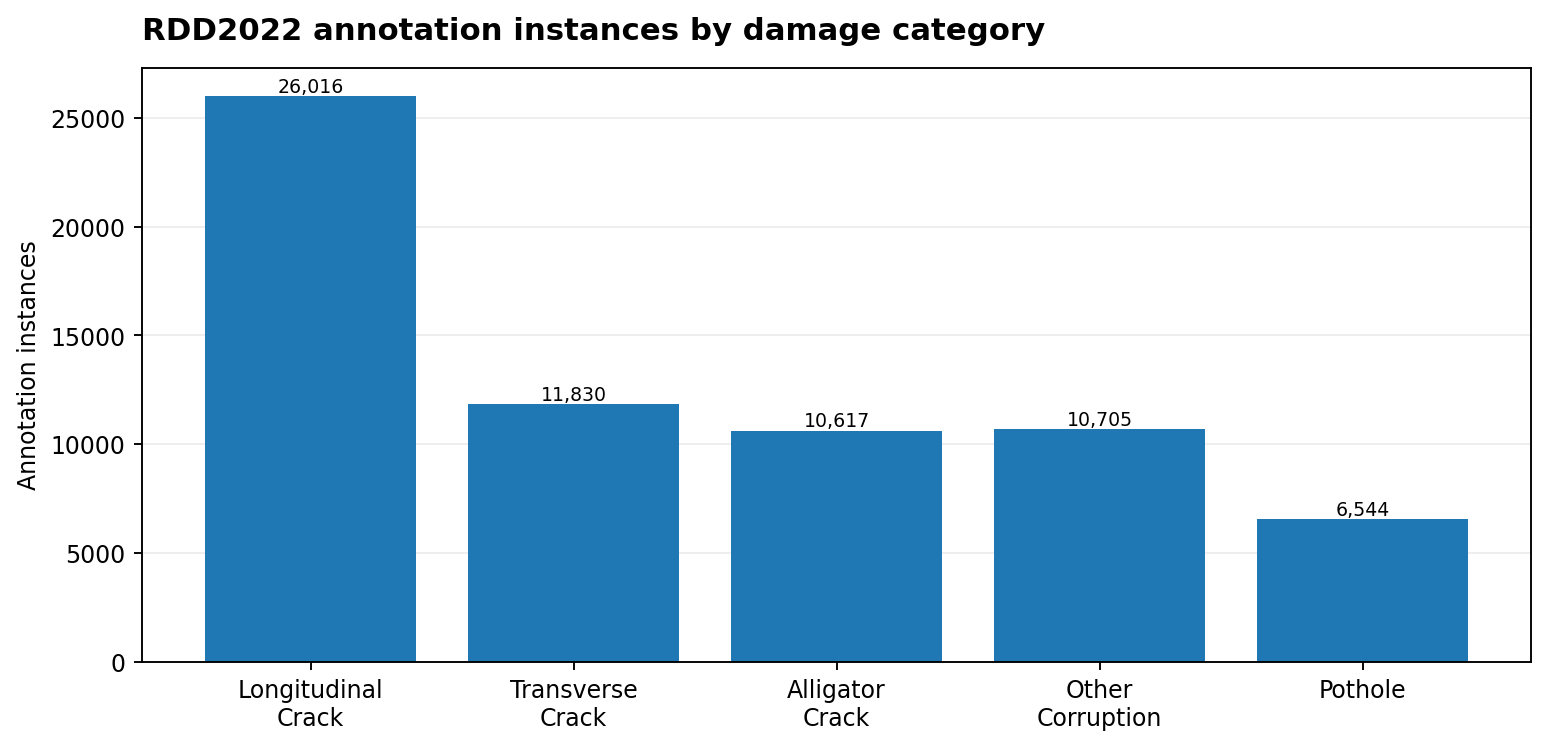


Class distribution:
 class_id
0.0    26016
1.0    11830
2.0    10617
3.0    10705
4.0     6544
Name: count, dtype: int64


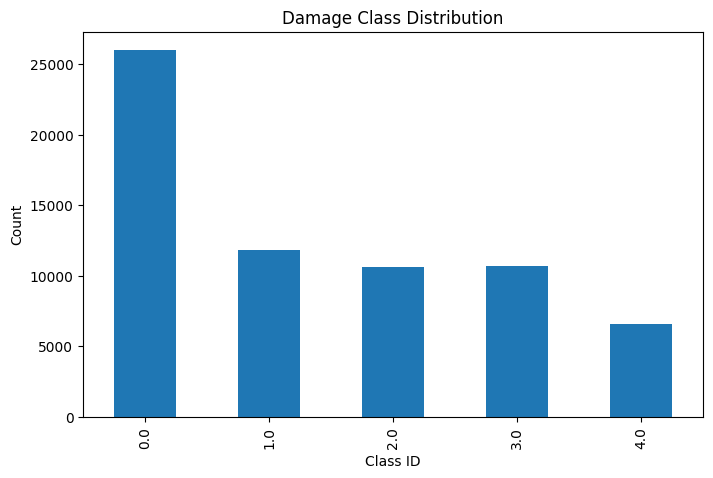

In [ ]:
class_counts = df['class_id'].dropna().value_counts().sort_index()
print("\nClass distribution:\n", class_counts)

plt.figure(figsize=(8,5))
class_counts.plot(kind='bar')
plt.title("Damage Class Distribution")
plt.xlabel("Class ID")
plt.ylabel("Count")
plt.savefig("class_distribution.png")
plt.show()

### 2.2 Geographic image coverage

The processed images span seven country/source groups. Japan and Norway contribute the largest image counts in this extracted table, followed by India. Geographic composition matters because surface texture, camera viewpoint, road construction and environmental conditions may vary between sources.
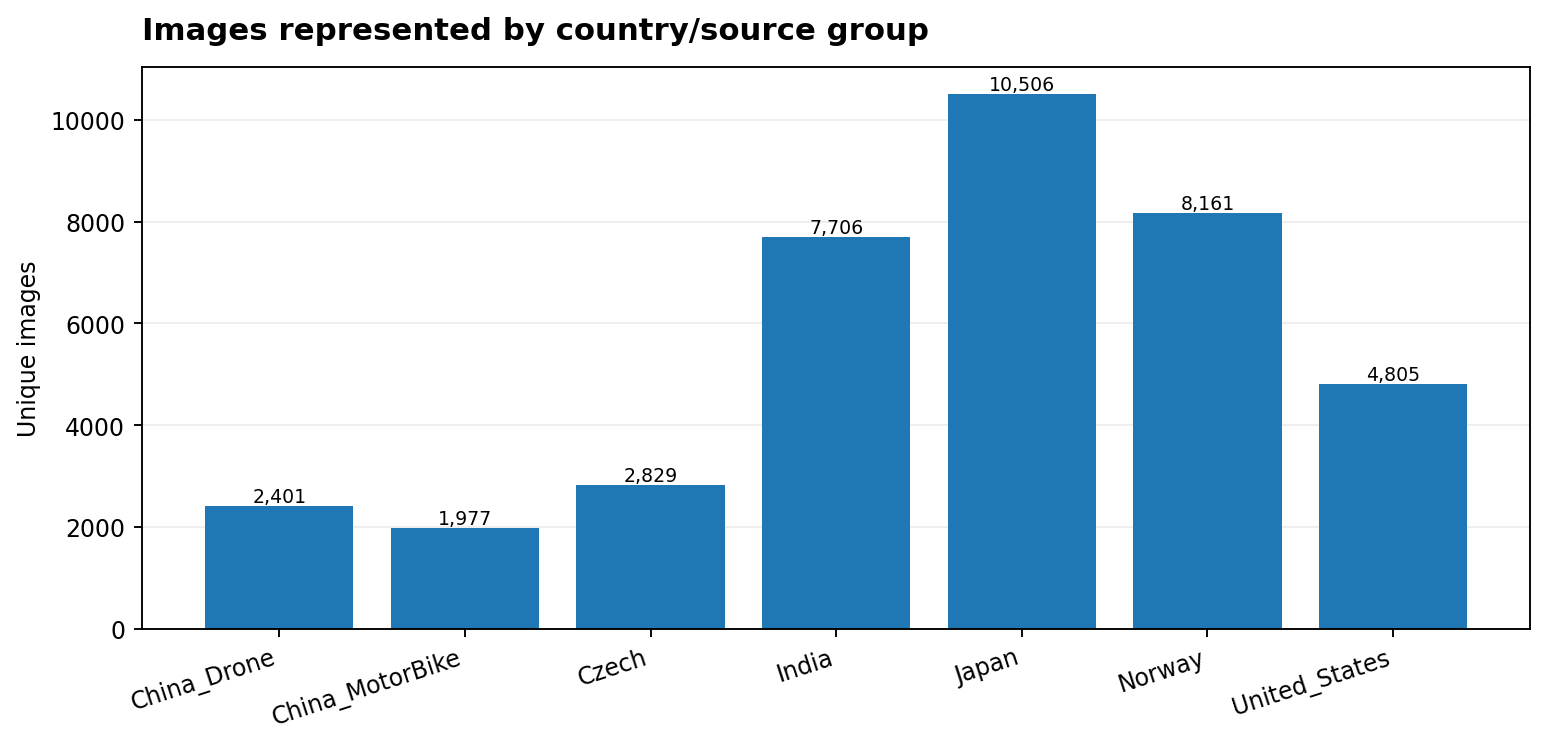


Images per country:
 country
China_Drone         2401
China_MotorBike     1977
Czech               2829
India               7706
Japan              10506
Norway              8161
United_States       4805
Name: file, dtype: int64


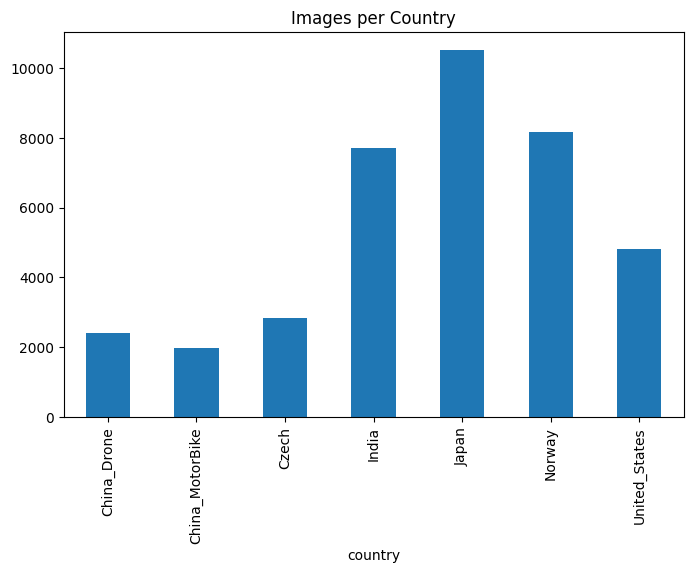

In [ ]:
country_counts = df.groupby('country')['file'].nunique()
print("\nImages per country:\n", country_counts)

plt.figure(figsize=(8,5))
country_counts.plot(kind='bar')
plt.title("Images per Country")
plt.savefig("country_distribution.png")
plt.show()

### 2.3 Country-by-class annotation composition

The heatmap shows the annotation counts by country/source and canonical damage category. The distribution is heterogeneous: for example, potholes are strongly represented in the India subset, while several categories have zero recorded instances in particular country groups. This reinforces the need to preserve source metadata during multi-source evaluation.
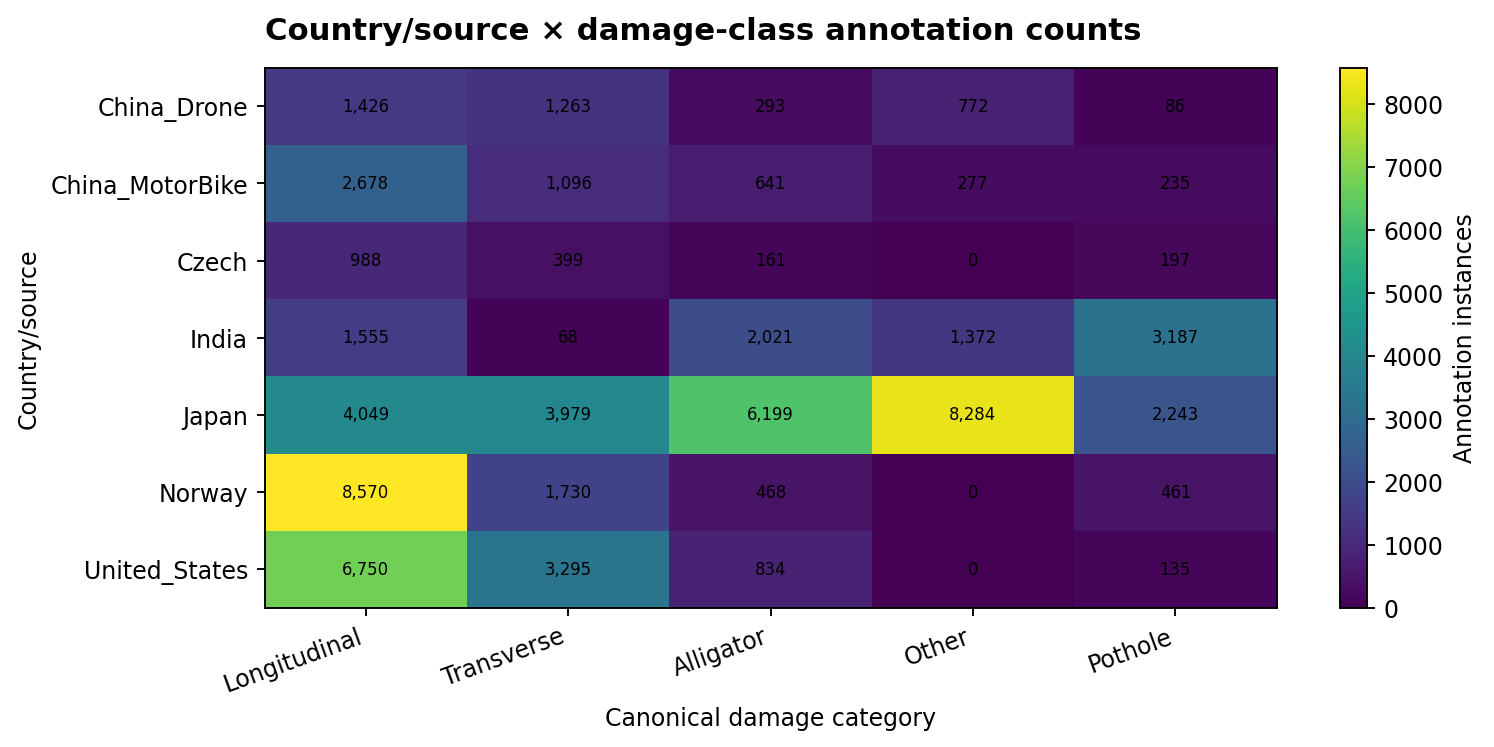


Class distribution by country:
 class_id          0.0   1.0   2.0   3.0   4.0
country                                      
China_Drone      1426  1263   293   772    86
China_MotorBike  2678  1096   641   277   235
Czech             988   399   161     0   197
India            1555    68  2021  1372  3187
Japan            4049  3979  6199  8284  2243
Norway           8570  1730   468     0   461
United_States    6750  3295   834     0   135


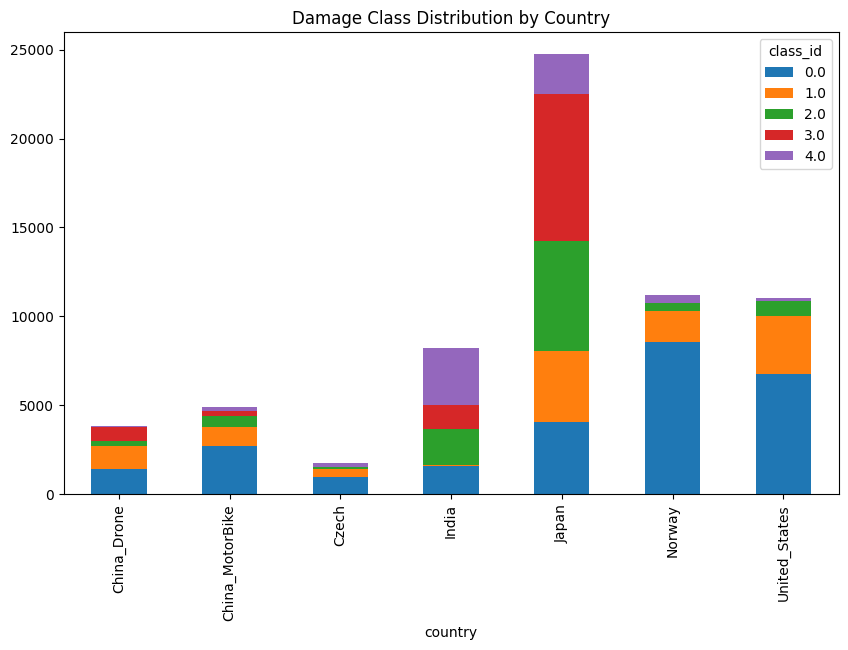

In [ ]:
cross = pd.crosstab(df['country'], df['class_id'])
print("\nClass distribution by country:\n", cross)

cross.plot(kind='bar', stacked=True, figsize=(10,6))
plt.title("Damage Class Distribution by Country")
plt.savefig("class_by_country.png")
plt.show()

### 2.4 Bounding-box scale and object density

The notebook reports normalized bounding-box area over **65,712 instances**: mean 0.0461, median 0.0152 and 75th percentile 0.0498. The median being substantially below the mean indicates a right-skewed distribution in which many defects occupy a relatively small fraction of the image. The image-level object-count summary covers 38,385 images, with a mean of 1.71 objects per image and a maximum of 44.

/tmp/ipykernel_4350/1176057494.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_boxes['area'] = df_boxes['width'] * df_boxes['height']



Bounding box area stats (normalized):
 count    65712.000000
mean         0.046118
std          0.079648
min          0.000000
25%          0.004825
50%          0.015176
75%          0.049783
max          0.940847
Name: area, dtype: float64


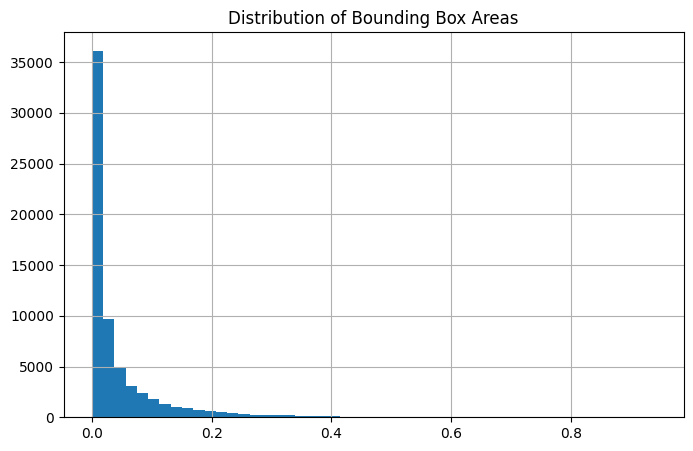

In [ ]:
df_boxes = df.dropna(subset=['width', 'height'])
df_boxes['area'] = df_boxes['width'] * df_boxes['height']

print("\nBounding box area stats (normalized):\n", df_boxes['area'].describe())

plt.figure(figsize=(8,5))
df_boxes['area'].hist(bins=50)
plt.title("Distribution of Bounding Box Areas")
plt.savefig("bbox_area_dist.png")
plt.show()


Objects per image stats:
 count    38385.000000
mean         1.711919
std          2.054314
min          0.000000
25%          0.000000
50%          1.000000
75%          2.000000
max         44.000000
Name: class_id, dtype: float64


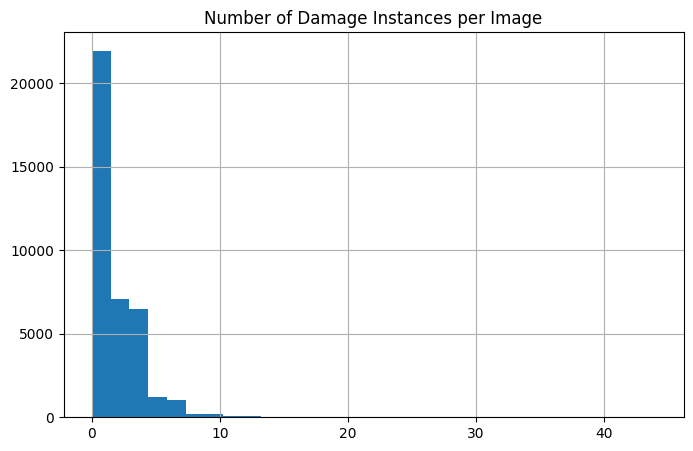

In [ ]:
objs_per_image = df.groupby('file')['class_id'].count()
print("\nObjects per image stats:\n", objs_per_image.describe())

plt.figure(figsize=(8,5))
objs_per_image.hist(bins=30)
plt.title("Number of Damage Instances per Image")
plt.savefig("objects_per_image.png")
plt.show()

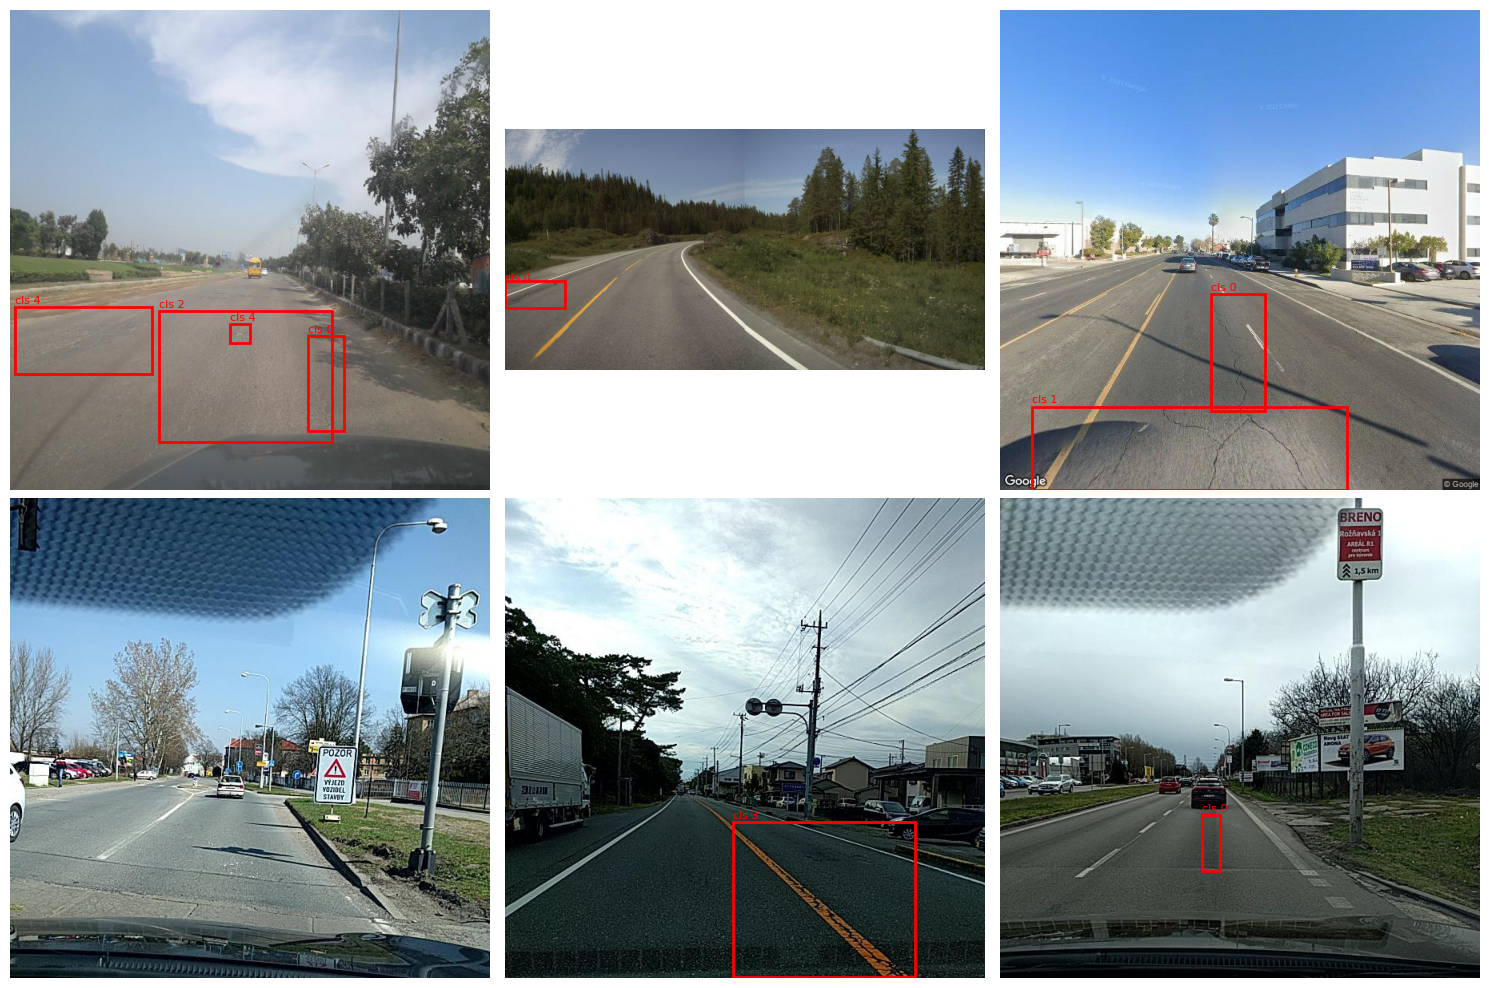

In [ ]:
import matplotlib.patches as patches

def show_sample(img_path, label_path, ax):
    img = Image.open(img_path)
    W, H = img.size
    ax.imshow(img)
    with open(label_path) as f:
        for line in f.readlines():
            cls, xc, yc, w, h = map(float, line.strip().split())
            x1 = (xc - w/2) * W
            y1 = (yc - h/2) * H
            rect = patches.Rectangle((x1, y1), w*W, h*H, linewidth=2, edgecolor='red', facecolor='none')
            ax.add_patch(rect)
            ax.text(x1, y1-5, f"cls {int(cls)}", color='red', fontsize=8)
    ax.axis('off')

train_img_dir = os.path.join(base, "train", "images")
train_lbl_dir = os.path.join(base, "train", "labels")
sample_files = [f for f in os.listdir(train_lbl_dir)][:6]

fig, axes = plt.subplots(2, 3, figsize=(15,10))
for ax, fname in zip(axes.flatten(), sample_files):
    img_file = fname.replace('.txt', '.jpg')
    show_sample(os.path.join(train_img_dir, img_file), os.path.join(train_lbl_dir, fname), ax)
plt.tight_layout()
plt.savefig("sample_annotations.png")
plt.show()

## 3. Classical computer-vision baseline: HOG + Linear SVM

**Objective.** Establish a non-deep-learning reference using Histogram of Oriented Gradients (HOG) features and a one-vs-rest Linear Support Vector Classifier. Images are resized and converted to grayscale before HOG extraction; image-level multi-label vectors are built from the YOLO annotations. A deterministic training subsample is used to keep feature extraction and fitting computationally tractable.

**Evaluation design.** Validation is used for an initial sanity check, while the held-out RDD2022 test split is reserved for final baseline reporting. Macro-F1 emphasizes performance across categories, whereas micro-F1 aggregates decisions across all labels. Hamming loss measures the fraction of incorrect label decisions.

### EDA interpretation

The data audit identifies three conditions that shape the later experiments: (i) uneven category frequency, (ii) country-dependent class composition and (iii) a substantial concentration of small bounding boxes. These observations motivate reporting class-wise metrics alongside aggregate scores and retaining geographic/source metadata wherever possible.

In [ ]:
import os
import numpy as np
import pandas as pd
from PIL import Image
from skimage.feature import hog
from skimage.color import rgb2gray
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, f1_score, hamming_loss
from tqdm import tqdm

In [ ]:
base = os.path.join(path, "RDD_SPLIT")
NUM_CLASSES = 5
IMG_SIZE = 128          # resize target, keeps HOG fast
TRAIN_SUBSAMPLE = 8000  # cap on training images for feasible Colab runtime
VAL_SUBSAMPLE = 2000
TEST_SUBSAMPLE = 2000

In [ ]:
# ---------- 1. Build multilabel vectors from YOLO label files ----------
def build_label_df(split):
    labels_dir = os.path.join(base, split, "labels")
    images_dir = os.path.join(base, split, "images")
    records = []
    for fname in os.listdir(labels_dir):
        label_vec = np.zeros(NUM_CLASSES, dtype=int)
        with open(os.path.join(labels_dir, fname), 'r') as f:
            lines = f.readlines()
        for line in lines:
            parts = line.strip().split()
            if len(parts) == 5:
                cls = int(parts[0])
                label_vec[cls] = 1
        img_file = fname.replace('.txt', '.jpg')
        records.append({
            "img_path": os.path.join(images_dir, img_file),
            "labels": label_vec
        })
    return pd.DataFrame(records)

print("Building label dataframes...")
train_df = build_label_df("train")
val_df = build_label_df("val")
test_df = build_label_df("test")
print(f"Train: {len(train_df)}, Val: {len(val_df)}, Test: {len(test_df)}")

Building label dataframes...
Train: 26869, Val: 5758, Test: 5758


In [ ]:
# ---------- 2. Subsample for feasible runtime ----------
np.random.seed(42)
train_df = train_df.sample(n=min(TRAIN_SUBSAMPLE, len(train_df)), random_state=42).reset_index(drop=True)
val_df = val_df.sample(n=min(VAL_SUBSAMPLE, len(val_df)), random_state=42).reset_index(drop=True)
test_df = test_df.sample(n=min(TEST_SUBSAMPLE, len(test_df)), random_state=42).reset_index(drop=True)
print(f"After subsampling -> Train: {len(train_df)}, Val: {len(val_df)}, Test: {len(test_df)}")


After subsampling -> Train: 8000, Val: 2000, Test: 2000


In [ ]:
# ---------- 3. Feature extraction: HOG on resized grayscale images ----------
def extract_hog_features(df):
    features = []
    for img_path in tqdm(df['img_path'], desc="Extracting HOG"):
        img = Image.open(img_path).convert('RGB').resize((IMG_SIZE, IMG_SIZE))
        gray = rgb2gray(np.array(img))
        feat = hog(gray, orientations=9, pixels_per_cell=(16, 16),
                    cells_per_block=(2, 2), block_norm='L2-Hys')
        features.append(feat)
    return np.array(features)

print("\nExtracting features for train set...")
X_train = extract_hog_features(train_df)
print("Extracting features for val set...")
X_val = extract_hog_features(val_df)
print("Extracting features for test set...")
X_test = extract_hog_features(test_df)

y_train = np.stack(train_df['labels'].values)
y_val = np.stack(val_df['labels'].values)
y_test = np.stack(test_df['labels'].values)

print(f"\nFeature shape: {X_train.shape}")  # (n_samples, n_hog_features)


Extracting features for train set...


Extracting HOG: 100%|██████████| 8000/8000 [06:13<00:00, 21.39it/s]


Extracting features for val set...


Extracting HOG: 100%|██████████| 2000/2000 [01:35<00:00, 21.00it/s]


Extracting features for test set...


Extracting HOG: 100%|██████████| 2000/2000 [01:27<00:00, 22.78it/s]


Feature shape: (8000, 1764)


In [ ]:
# ---------- 4. Train multilabel SVM ----------
print("\nTraining OneVsRestClassifier(LinearSVC)...")
clf = OneVsRestClassifier(LinearSVC(max_iter=5000, class_weight='balanced'))
clf.fit(X_train, y_train)


Training OneVsRestClassifier(LinearSVC)...


OneVsRestClassifier(estimator=LinearSVC(class_weight='balanced', max_iter=5000))

In [ ]:
# ---------- 5. Evaluate on val set first (sanity check before touching test) ----------
print("\n--- Validation Set Results ---")
y_val_pred = clf.predict(X_val)
class_names = ['Longitudinal Crack', 'Transverse Crack', 'Alligator Crack', 'Other Corruption', 'Pothole']
print(classification_report(y_val, y_val_pred, target_names=class_names, zero_division=0))
print("Macro-F1:", f1_score(y_val, y_val_pred, average='macro', zero_division=0))
print("Micro-F1:", f1_score(y_val, y_val_pred, average='micro', zero_division=0))
print("Hamming Loss:", hamming_loss(y_val, y_val_pred))



--- Validation Set Results ---
                    precision    recall  f1-score   support

Longitudinal Crack       0.52      0.63      0.57       681
  Transverse Crack       0.35      0.57      0.43       385
   Alligator Crack       0.39      0.63      0.48       412
  Other Corruption       0.46      0.70      0.56       391
           Pothole       0.21      0.48      0.29       189

         micro avg       0.41      0.62      0.49      2058
         macro avg       0.39      0.60      0.47      2058
      weighted avg       0.42      0.62      0.50      2058
       samples avg       0.32      0.42      0.34      2058

Macro-F1: 0.46700827956013435
Micro-F1: 0.4895212459142473
Hamming Loss: 0.2655


### 3.1 Classical baseline: held-out test performance

The recorded HOG + Linear SVM test evaluation reports a **macro-F1 of 0.4667**, **micro-F1 of 0.4954** and **Hamming loss of 0.2683**. Potholes have the lowest class F1 (0.29), while longitudinal cracks have the highest (0.61). This is an image-level multi-label classification baseline; it does not produce object bounding boxes and must not be compared numerically with detector mAP.
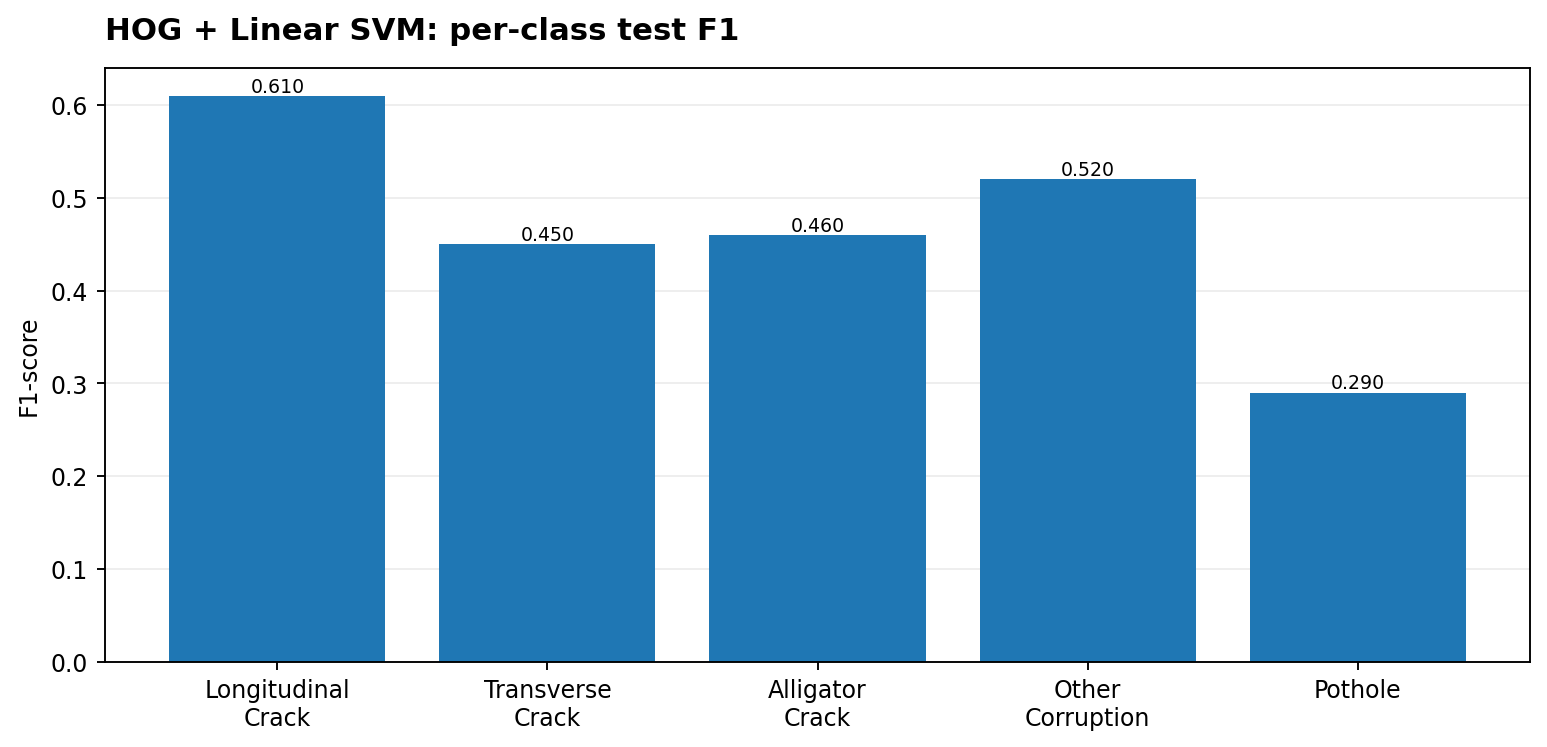

In [ ]:
# ---------- 6. Final evaluation on test set ----------
print("\n--- Test Set Results (final baseline numbers) ---")
y_test_pred = clf.predict(X_test)
print(classification_report(y_test, y_test_pred, target_names=class_names, zero_division=0))
print("Macro-F1:", f1_score(y_test, y_test_pred, average='macro', zero_division=0))
print("Micro-F1:", f1_score(y_test, y_test_pred, average='micro', zero_division=0))
print("Hamming Loss:", hamming_loss(y_test, y_test_pred))


--- Test Set Results (final baseline numbers) ---
                    precision    recall  f1-score   support

Longitudinal Crack       0.57      0.67      0.61       745
  Transverse Crack       0.35      0.61      0.45       389
   Alligator Crack       0.37      0.62      0.46       413
  Other Corruption       0.44      0.63      0.52       381
           Pothole       0.20      0.51      0.29       175

         micro avg       0.41      0.63      0.50      2103
         macro avg       0.39      0.61      0.47      2103
      weighted avg       0.44      0.63      0.51      2103
       samples avg       0.33      0.43      0.35      2103

Macro-F1: 0.4667344271912956
Micro-F1: 0.49539213842392327
Hamming Loss: 0.2683


In [ ]:
import os
os.makedirs('/content/drive/MyDrive/road_damage_project', exist_ok=True)

import joblib
joblib.dump(clf, '/content/drive/MyDrive/road_damage_project/svm_baseline.pkl')
np.save('/content/drive/MyDrive/road_damage_project/X_train.npy', X_train)
np.save('/content/drive/MyDrive/road_damage_project/y_train.npy', y_train)
np.save('/content/drive/MyDrive/road_damage_project/X_val.npy', X_val)
np.save('/content/drive/MyDrive/road_damage_project/y_val.npy', y_val)
np.save('/content/drive/MyDrive/road_damage_project/X_test.npy', X_test)
np.save('/content/drive/MyDrive/road_damage_project/y_test.npy', y_test)

print("Checkpoint saved successfully.")

## 4. Persisting and reloading the classical baseline

The following cells preserve the fitted estimator and intermediate arrays in Google Drive, then reload them for subsequent experiments. This checkpoint stage separates expensive feature extraction and model fitting from later dataset-harmonization work. The notebook uses Google Colab Drive paths; these paths must exist in the active runtime.

In [ ]:
import shutil
shutil.rmtree('/content/drive', ignore_errors=True)

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
checkpoint_dir = '/content/drive/MyDrive/road_damage_project'
if os.path.exists(checkpoint_dir):
    print("Files found:", os.listdir(checkpoint_dir))
else:
    print("Folder doesn't exist — checkpoint was never saved")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Files found: ['svm_baseline.pkl', 'X_train.npy', 'y_train.npy', 'X_val.npy', 'y_val.npy', 'X_test.npy', 'y_test.npy']


In [ ]:
import joblib
import numpy as np

clf = joblib.load('/content/drive/MyDrive/road_damage_project/svm_baseline.pkl')
X_train = np.load('/content/drive/MyDrive/road_damage_project/X_train.npy')
y_train = np.load('/content/drive/MyDrive/road_damage_project/y_train.npy')
X_val = np.load('/content/drive/MyDrive/road_damage_project/X_val.npy')
y_val = np.load('/content/drive/MyDrive/road_damage_project/y_val.npy')
X_test = np.load('/content/drive/MyDrive/road_damage_project/X_test.npy')
y_test = np.load('/content/drive/MyDrive/road_damage_project/y_test.npy')

print("Reloaded successfully.")
print("clf:", clf)
print("X_train shape:", X_train.shape)

Reloaded successfully.
clf: OneVsRestClassifier(estimator=LinearSVC(class_weight='balanced', max_iter=5000))
X_train shape: (8000, 1764)


## 5. RDD2024 integration: source taxonomy and label harmonization

**Objective.** Incorporate compatible RDD2024 annotations while retaining the project's five-class label convention. RDD2024 uses country-specific class-index definitions, so a source index must first be interpreted through the relevant country `data.yaml` mapping. Only after resolving the source index to its damage code can the code be mapped to the TarmacLook canonical class ID.

**Harmonization policy.** The mapping retained by the implementation is explicit: D00 → Longitudinal Crack, D10 → Transverse Crack, D20 → Alligator Crack and D40 → Pothole. Source categories without a clean mapping in the current five-class taxonomy are excluded from this merged experiment. `Other Corruption` remains part of the TarmacLook target taxonomy but is not assigned an RDD2024 code in the mapping shown below; this distinction should be preserved when interpreting source coverage.

In [ ]:
import kagglehub
path = kagglehub.dataset_download("aliabdelmenam/rdd-2022")
print("RDD2022 path:", path)

Using Colab cache for faster access to the 'rdd-2022' dataset.
RDD2022 path: /kaggle/input/rdd-2022


In [ ]:
path_2024 = kagglehub.dataset_download("sannyshankaranml/n-rdd2024")
print("RDD2024 path:", path_2024)

100%|██████████| 6.04G/6.04G [01:21<00:00, 79.7MB/s]

Extracting files...


RDD2024 path: /root/.cache/kagglehub/datasets/sannyshankaranml/n-rdd2024/versions/1


In [ ]:
import yaml
import glob

# ---------- 1. Build per-country index -> D-code mapping from each data.yaml ----------
RDD2024_ROOT = os.path.join(path_2024, "N-RDD2024Road damage and defects", "Training and Validation Dataset")

country_folders = [f for f in os.listdir(RDD2024_ROOT) if f.endswith("_txt")]
print("Country folders found:", country_folders)

country_class_maps = {}  # country_folder -> {index: D-code}
for cf in country_folders:
    yaml_path = os.path.join(RDD2024_ROOT, cf, "data.yaml")
    with open(yaml_path) as f:
        data = yaml.safe_load(f)
    idx_to_dcode = {i: name for i, name in enumerate(data['names'])}
    country_class_maps[cf] = idx_to_dcode
    print(f"{cf}: {idx_to_dcode}")

Country folders found: ['japan_txt', 'norway_txt', 'china-motorbike_txt', 'USA_txt', 'india_txt', 'Czech Republic_txt']
japan_txt: {0: 'D00', 1: 'D10', 2: 'D20', 3: 'D30', 4: 'D40', 5: 'D50', 6: 'D60', 7: 'D70', 8: 'D80', 9: 'D90'}
norway_txt: {0: 'D00', 1: 'D10', 2: 'D20', 3: 'D40', 4: 'D50', 5: 'D60', 6: 'D70', 7: 'D80', 8: 'D90'}
china-motorbike_txt: {0: 'D00', 1: 'D10', 2: 'D20', 3: 'D40', 4: 'D50', 5: 'D60', 6: 'D70', 7: 'D80'}
USA_txt: {0: 'D00', 1: 'D10', 2: 'D20', 3: 'D30', 4: 'D40', 5: 'D50', 6: 'D60', 7: 'D70', 8: 'D80', 9: 'D90'}
india_txt: {0: 'D00', 1: 'D10', 2: 'D20', 3: 'D40', 4: 'D50', 5: 'D60', 6: 'D70', 7: 'D80'}
Czech Republic_txt: {0: 'D00', 1: 'D10', 2: 'D20', 3: 'D30', 4: 'D40', 5: 'D50', 6: 'D60', 7: 'D70', 8: 'D80', 9: 'D90'}


In [ ]:
# ---------- 2. D-code -> RDD2022 class ID (only keep the 4 that map cleanly) ----------
DCODE_TO_RDD2022_CLASS = {
    'D00': 0,  # Longitudinal Crack
    'D10': 1,  # Transverse Crack
    'D20': 2,  # Alligator Crack
    'D40': 4,  # Pothole
    # D30, D50, D60, D70, D80, D90 -> dropped (not merged)
}

In [ ]:
# ---------- 3. Build harmonized multilabel records from RDD2024 (train + valid folders) ----------
import pandas as pd
import numpy as np

NUM_CLASSES = 5
rdd2024_records = []

for cf in country_folders:
    idx_to_dcode = country_class_maps[cf]
    for split in ["train", "valid"]:
        labels_dir = os.path.join(RDD2024_ROOT, cf, split, "labels")
        images_dir = os.path.join(RDD2024_ROOT, cf, split, "images")
        if not os.path.exists(labels_dir):
            continue
        for fname in os.listdir(labels_dir):
            label_vec = np.zeros(NUM_CLASSES, dtype=int)
            kept_any = False
            with open(os.path.join(labels_dir, fname), 'r') as f:
                lines = f.readlines()
            for line in lines:
                parts = line.strip().split()
                if len(parts) != 5:
                    continue
                idx = int(parts[0])
                dcode = idx_to_dcode.get(idx)
                if dcode in DCODE_TO_RDD2022_CLASS:
                    label_vec[DCODE_TO_RDD2022_CLASS[dcode]] = 1
                    kept_any = True


            img_file = fname.replace('.txt', '.jpg')
            img_path = os.path.join(images_dir, img_file)
            if os.path.exists(img_path):
                rdd2024_records.append({
                    "img_path": img_path,
                    "labels": label_vec,
                    "source": "rdd2024",
                    "country": cf.replace("_txt", "")
                })

rdd2024_df = pd.DataFrame(rdd2024_records)
print(f"\nRDD2024 harmonized records: {len(rdd2024_df)}")
print("Images with at least one kept damage type:", sum(rdd2024_df['labels'].apply(lambda x: x.sum() > 0)))
print("Images that became background (all dropped classes only):", sum(rdd2024_df['labels'].apply(lambda x: x.sum() == 0)))


RDD2024 harmonized records: 18995
Images with at least one kept damage type: 17702
Images that became background (all dropped classes only): 1293


In [ ]:
import os
os.makedirs('/content/drive/MyDrive/road_damage_project', exist_ok=True)

# Save the harmonized RDD2024 dataframe
rdd2024_df.to_pickle('/content/drive/MyDrive/road_damage_project/rdd2024_harmonized.pkl')

print("Saved rdd2024_df with", len(rdd2024_df), "records.")
print("Checkpoint complete.")

Saved rdd2024_df with 18995 records.
Checkpoint complete.


In [ ]:
# 1. Mount drive
from google.colab import drive
drive.mount('/content/drive')

# 2. Reload baseline SVM + features
import joblib, numpy as np, pandas as pd
clf = joblib.load('/content/drive/MyDrive/road_damage_project/svm_baseline.pkl')
X_train = np.load('/content/drive/MyDrive/road_damage_project/X_train.npy')
y_train = np.load('/content/drive/MyDrive/road_damage_project/y_train.npy')
X_val = np.load('/content/drive/MyDrive/road_damage_project/X_val.npy')
y_val = np.load('/content/drive/MyDrive/road_damage_project/y_val.npy')
X_test = np.load('/content/drive/MyDrive/road_damage_project/X_test.npy')
y_test = np.load('/content/drive/MyDrive/road_damage_project/y_test.npy')

# 3. Reload harmonized RDD2024 labels
rdd2024_df = pd.read_pickle('/content/drive/MyDrive/road_damage_project/rdd2024_harmonized.pkl')

# 4. Re-download datasets (only needed if you're extracting NEW features from RDD2024 images)
import kagglehub
path = kagglehub.dataset_download("aliabdelmenam/rdd-2022")
path_2024 = kagglehub.dataset_download("sannyshankaranml/n-rdd2024")

print("Everything reloaded, ready to continue.")

Mounted at /content/drive


100%|██████████| 9.90G/9.90G [04:20<00:00, 40.8MB/s]

Extracting files...


100%|██████████| 6.04G/6.04G [02:50<00:00, 38.0MB/s]

Extracting files...


Everything reloaded, ready to continue.


## 6. Rebuilding the merged classical experiment

This stage reconstructs the RDD2022 image-level labels, combines them with harmonized RDD2024 records and creates a reproducible random training subsample. HOG features are extracted once for the selected images. The subsequent oversampling step duplicates minority-class rows to raise their representation relative to the majority class; it does not synthesize new image content.

**Evaluation safeguard.** The merged/oversampled model is evaluated against the original, untouched RDD2022 test set. This allows a controlled comparison against the initial classical baseline, although the training distribution and feature sample differ between the two experiments.

In [ ]:
import os
# ---------- Rebuild full RDD2022 label dataframes (not the 8000-subsampled version) ----------
def build_rdd2022_label_df(split):
    labels_dir = os.path.join(path, "RDD_SPLIT", split, "labels")
    images_dir = os.path.join(path, "RDD_SPLIT", split, "images")
    records = []
    for fname in os.listdir(labels_dir):
        label_vec = np.zeros(5, dtype=int)
        with open(os.path.join(labels_dir, fname), 'r') as f:
            lines = f.readlines()
        for line in lines:
            parts = line.strip().split()
            if len(parts) == 5:
                cls = int(parts[0])
                label_vec[cls] = 1
        img_file = fname.replace('.txt', '.jpg')
        records.append({
            "img_path": os.path.join(images_dir, img_file),
            "labels": label_vec,
            "source": "rdd2022"
        })
    return pd.DataFrame(records)

rdd2022_train_full = build_rdd2022_label_df("train")
rdd2022_val_full = build_rdd2022_label_df("val")
rdd2022_test_full = build_rdd2022_label_df("test")

# ---------- Merged training set: RDD2022 train + RDD2024 (train+valid combined earlier) ----------
merged_train_df = pd.concat([rdd2022_train_full, rdd2024_df], ignore_index=True)

# ---------- Image count summary ----------
print("=== IMAGE COUNTS ===")
print(f"RDD2022 - train: {len(rdd2022_train_full)}, val: {len(rdd2022_val_full)}, test: {len(rdd2022_test_full)}")
print(f"RDD2024 harmonized (all, incl. background-only): {len(rdd2024_df)}")
print(f"RDD2024 harmonized (with at least 1 kept class): {sum(rdd2024_df['labels'].apply(lambda x: x.sum() > 0))}")
print(f"Merged training set (RDD2022 train + RDD2024): {len(merged_train_df)}")

# ---------- Per-class instance count comparison ----------
class_names = ['Longitudinal Crack', 'Transverse Crack', 'Alligator Crack', 'Other Corruption', 'Pothole']

def class_instance_counts(df, name):
    counts = np.stack(df['labels'].values).sum(axis=0)
    print(f"\n{name}:")
    for cn, c in zip(class_names, counts):
        print(f"  {cn}: {int(c)}")

print("\n=== PER-CLASS INSTANCE COUNTS ===")
class_instance_counts(rdd2022_train_full, "RDD2022 train (original)")
class_instance_counts(rdd2024_df, "RDD2024 harmonized")
class_instance_counts(merged_train_df, "Merged training set")

=== IMAGE COUNTS ===
RDD2022 - train: 26869, val: 5758, test: 5758
RDD2024 harmonized (all, incl. background-only): 18995
RDD2024 harmonized (with at least 1 kept class): 17702
Merged training set (RDD2022 train + RDD2024): 45864

=== PER-CLASS INSTANCE COUNTS ===

RDD2022 train (original):
  Longitudinal Crack: 9457
  Transverse Crack: 5433
  Alligator Crack: 5976
  Other Corruption: 5247
  Pothole: 2599

RDD2024 harmonized:
  Longitudinal Crack: 11011
  Transverse Crack: 6348
  Alligator Crack: 6039
  Other Corruption: 0
  Pothole: 2287

Merged training set:
  Longitudinal Crack: 20468
  Transverse Crack: 11781
  Alligator Crack: 12015
  Other Corruption: 5247
  Pothole: 4886


In [ ]:
import numpy as np
import pandas as pd
from skimage.feature import hog
from skimage.color import rgb2gray
from PIL import Image
from tqdm import tqdm
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, f1_score, hamming_loss

np.random.seed(42)
class_names = ['Longitudinal Crack', 'Transverse Crack', 'Alligator Crack', 'Other Corruption', 'Pothole']
TARGET_SUBSAMPLE = 15000
IMG_SIZE = 128



In [ ]:
# ---------- Corrected: pure random subsample, no forced quotas ----------
np.random.seed(42)
subsample_idx = np.random.choice(len(merged_train_df), size=TARGET_SUBSAMPLE, replace=False)
subsample_df = merged_train_df.iloc[subsample_idx].reset_index(drop=True)

sub_labels = np.stack(subsample_df['labels'].values)
print("Subsample per-class instance counts (BEFORE oversampling, true random):")
for c in range(5):
    print(f"  {class_names[c]}: {sub_labels[:, c].sum()}")

Subsample per-class instance counts (BEFORE oversampling, true random):
  Longitudinal Crack: 6663
  Transverse Crack: 3881
  Alligator Crack: 3953
  Other Corruption: 1692
  Pothole: 1624


In [ ]:
# ---------- 2. Extract HOG features ONCE per unique image in subsample ----------
def extract_hog_features(df):
    features = []
    for img_path in tqdm(df['img_path'], desc="Extracting HOG"):
        img = Image.open(img_path).convert('RGB').resize((IMG_SIZE, IMG_SIZE))
        gray = rgb2gray(np.array(img))
        feat = hog(gray, orientations=9, pixels_per_cell=(16, 16),
                    cells_per_block=(2, 2), block_norm='L2-Hys')
        features.append(feat)
    return np.array(features)

print("Extracting features for merged subsample (this will take a while)...")
X_subsample = extract_hog_features(subsample_df)
y_subsample = sub_labels
print(f"Feature matrix shape: {X_subsample.shape}")

Extracting features for merged subsample (this will take a while)...


Extracting HOG: 100%|██████████| 15000/15000 [09:22<00:00, 26.68it/s]


Feature matrix shape: (15000, 1764)


In [ ]:
# ---------- 3. Oversample minority classes (duplicate rows, no recomputation) ----------
OVERSAMPLE_TARGET_RATIO = 0.6  # boost minority classes to at least 60% of majority class count

majority_count = sub_labels.sum(axis=0).max()
oversample_indices = list(range(len(subsample_df)))

for c in range(5):
    current_count = sub_labels[:, c].sum()
    target_count = int(majority_count * OVERSAMPLE_TARGET_RATIO)
    if current_count < target_count and current_count > 0:
        needed = target_count - current_count
        class_rows = np.where(sub_labels[:, c] == 1)[0]
        extra = np.random.choice(class_rows, size=needed, replace=True)
        oversample_indices.extend(extra.tolist())
        print(f"{class_names[c]}: {current_count} -> ~{target_count} (added {needed} duplicated rows)")

X_train_merged = X_subsample[oversample_indices]
y_train_merged = y_subsample[oversample_indices]
print(f"\nFinal oversampled training set: {X_train_merged.shape}")

print("\nFinal per-class instance counts after oversampling:")
for c in range(5):
    print(f"  {class_names[c]}: {y_train_merged[:, c].sum()}")

Transverse Crack: 3881 -> ~3997 (added 116 duplicated rows)
Alligator Crack: 3953 -> ~3997 (added 44 duplicated rows)
Other Corruption: 1692 -> ~3997 (added 2305 duplicated rows)
Pothole: 1624 -> ~3997 (added 2373 duplicated rows)

Final oversampled training set: (19838, 1764)

Final per-class instance counts after oversampling:
  Longitudinal Crack: 7884
  Transverse Crack: 4683
  Alligator Crack: 5908
  Other Corruption: 4282
  Pothole: 4262


In [ ]:
# ---------- 4. Retrain SVM ----------
print("\nTraining new SVM on merged + oversampled data...")
clf_v2 = OneVsRestClassifier(LinearSVC(max_iter=5000, class_weight='balanced'))
clf_v2.fit(X_train_merged, y_train_merged)


Training new SVM on merged + oversampled data...


OneVsRestClassifier(estimator=LinearSVC(class_weight='balanced', max_iter=5000))

In [ ]:
# ---------- 5. Evaluate on ORIGINAL, untouched RDD2022 test set ----------
print("\n--- Test Set Results: Merged + Oversampled Model ---")
y_test_pred_v2 = clf_v2.predict(X_test)
print(classification_report(y_test, y_test_pred_v2, target_names=class_names, zero_division=0))
print("Macro-F1:", f1_score(y_test, y_test_pred_v2, average='macro', zero_division=0))
print("Micro-F1:", f1_score(y_test, y_test_pred_v2, average='micro', zero_division=0))
print("Hamming Loss:", hamming_loss(y_test, y_test_pred_v2))


--- Test Set Results: Merged + Oversampled Model ---
                    precision    recall  f1-score   support

Longitudinal Crack       0.56      0.68      0.62       745
  Transverse Crack       0.35      0.64      0.46       389
   Alligator Crack       0.43      0.65      0.51       413
  Other Corruption       0.42      0.54      0.47       381
           Pothole       0.21      0.62      0.32       175

         micro avg       0.41      0.64      0.50      2103
         macro avg       0.39      0.63      0.48      2103
      weighted avg       0.44      0.64      0.52      2103
       samples avg       0.35      0.44      0.37      2103

Macro-F1: 0.47533529930816387
Micro-F1: 0.5021499345672088
Hamming Loss: 0.2663


### 5.1 Baseline versus merged/oversampled SVM

On the original RDD2022 test split, macro-F1 changes from **0.4667 to 0.4753** and micro-F1 from **0.4954 to 0.5021** after the merged-data and oversampling experiment. Pothole F1 increases from 0.29 to 0.32, while the other categories show mixed changes. The aggregate improvement is modest; it should be interpreted alongside the per-class trade-offs and the fact that oversampling duplicates existing training examples.
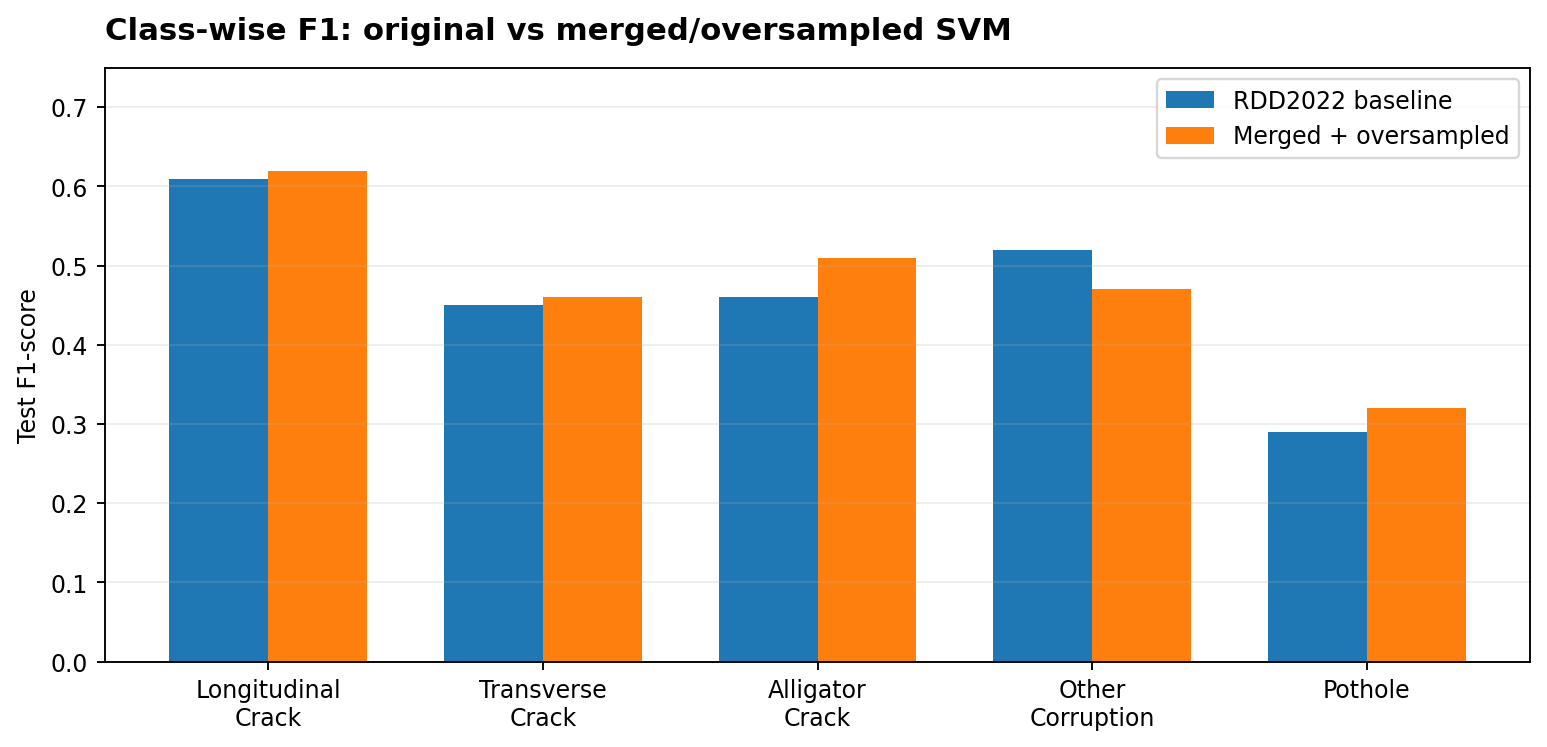

In [ ]:
print("\n--- Comparison: Week 1 Baseline vs Merged+Oversampled ---")
y_test_pred_v1 = clf.predict(X_test)
print("Week 1 Macro-F1:", f1_score(y_test, y_test_pred_v1, average='macro', zero_division=0))
print("Merged+Oversampled Macro-F1:", f1_score(y_test, y_test_pred_v2, average='macro', zero_division=0))


--- Comparison: Week 1 Baseline vs Merged+Oversampled ---
Week 1 Macro-F1: 0.4667344271912956
Merged+Oversampled Macro-F1: 0.47533529930816387


### Classical baseline result summary

| Metric | Original RDD2022 baseline | Merged + oversampled |
|---|---:|---:|
| Macro-F1 | 0.4667 | 0.4753 |
| Micro-F1 | 0.4954 | 0.5021 |
| Hamming loss | 0.2683 | 0.2663 |

The comparison suggests a small aggregate gain on the held-out RDD2022 test set. It does not establish that source mixing or oversampling alone caused the change, because the merged experiment also changes the training sample composition and number of training records.


In [ ]:
import os, joblib, numpy as np

os.makedirs('/content/drive/MyDrive/road_damage_project', exist_ok=True)

# New model + merged/oversampled training data
joblib.dump(clf_v2, '/content/drive/MyDrive/road_damage_project/svm_merged_oversampled.pkl')
np.save('/content/drive/MyDrive/road_damage_project/X_train_merged.npy', X_train_merged)
np.save('/content/drive/MyDrive/road_damage_project/y_train_merged.npy', y_train_merged)

# Save the subsample BEFORE oversampling too (features + labels) — needed for the before/after distribution plots later
np.save('/content/drive/MyDrive/road_damage_project/X_subsample.npy', X_subsample)
np.save('/content/drive/MyDrive/road_damage_project/y_subsample.npy', y_subsample)
subsample_df.to_pickle('/content/drive/MyDrive/road_damage_project/subsample_df.pkl')

# Save test predictions from both models for your report tables, so you don't need to rerun predict()
np.save('/content/drive/MyDrive/road_damage_project/y_test_pred_v1.npy', y_test_pred_v1)
np.save('/content/drive/MyDrive/road_damage_project/y_test_pred_v2.npy', y_test_pred_v2)

print("Checkpoint saved:")
for f in os.listdir('/content/drive/MyDrive/road_damage_project'):
    print(" -", f)

Checkpoint saved:
 - svm_baseline.pkl
 - X_train.npy
 - y_train.npy
 - X_val.npy
 - y_val.npy
 - X_test.npy
 - y_test.npy
 - rdd2024_harmonized.pkl
 - svm_merged_oversampled.pkl
 - X_train_merged.npy
 - y_train_merged.npy
 - X_subsample.npy
 - y_subsample.npy
 - subsample_df.pkl
 - y_test_pred_v1.npy
 - y_test_pred_v2.npy


In [3]:
# 1. Mount Drive
from google.colab import drive
drive.mount('/content/drive')

# 2. Reload everything from previous checkpoints
import joblib, numpy as np, pandas as pd

clf = joblib.load('/content/drive/MyDrive/road_damage_project/svm_baseline.pkl')
X_train = np.load('/content/drive/MyDrive/road_damage_project/X_train.npy')
y_train = np.load('/content/drive/MyDrive/road_damage_project/y_train.npy')
X_val = np.load('/content/drive/MyDrive/road_damage_project/X_val.npy')
y_val = np.load('/content/drive/MyDrive/road_damage_project/y_val.npy')
X_test = np.load('/content/drive/MyDrive/road_damage_project/X_test.npy')
y_test = np.load('/content/drive/MyDrive/road_damage_project/y_test.npy')

rdd2024_df = pd.read_pickle('/content/drive/MyDrive/road_damage_project/rdd2024_harmonized.pkl')

clf_v2 = joblib.load('/content/drive/MyDrive/road_damage_project/svm_merged_oversampled.pkl')
X_train_merged = np.load('/content/drive/MyDrive/road_damage_project/X_train_merged.npy')
y_train_merged = np.load('/content/drive/MyDrive/road_damage_project/y_train_merged.npy')
X_subsample = np.load('/content/drive/MyDrive/road_damage_project/X_subsample.npy')
y_subsample = np.load('/content/drive/MyDrive/road_damage_project/y_subsample.npy')
subsample_df = pd.read_pickle('/content/drive/MyDrive/road_damage_project/subsample_df.pkl')
y_test_pred_v1 = np.load('/content/drive/MyDrive/road_damage_project/y_test_pred_v1.npy')
y_test_pred_v2 = np.load('/content/drive/MyDrive/road_damage_project/y_test_pred_v2.npy')

# 3. Re-download raw datasets (needed for actual image/label files — YOLO work needs raw files, not just cached features)
import kagglehub
path = kagglehub.dataset_download("aliabdelmenam/rdd-2022")
path_2024 = kagglehub.dataset_download("sannyshankaranml/n-rdd2024")

print("Everything reloaded. path (RDD2022):", path)
print("path_2024 (RDD2024):", path_2024)
print("Ready to start YOLO phase.")

Mounted at /content/drive
Using Colab cache for faster access to the 'rdd-2022' dataset.


100%|██████████| 6.04G/6.04G [01:05<00:00, 99.3MB/s]

Extracting files...


Everything reloaded. path (RDD2022): /kaggle/input/rdd-2022
path_2024 (RDD2024): /root/.cache/kagglehub/datasets/sannyshankaranml/n-rdd2024/versions/1
Ready to start YOLO phase.


## 7. Unified object-detection dataset construction

**Objective.** Construct a YOLO-format dataset in which compatible RDD2024 bounding boxes are remapped to the canonical TarmacLook class IDs and added to the training partition. The RDD2022 validation images remain the held-out validation partition in the implementation. The notebook preserves the original normalized box coordinates and changes the class identifier only when a source label is successfully mapped.

**Important split detail.** The RDD2024 `train` and `valid` folders are both routed into the merged training directory in the supplied implementation. The validation directory is populated from RDD2022 validation data. Therefore, this is not a fully independent cross-source validation design; RDD2024 does not contribute a separate validation partition in this workflow.

In [4]:
import os
import yaml
import shutil
from tqdm import tqdm

RDD2024_ROOT = os.path.join(path_2024, "N-RDD2024Road damage and defects", "Training and Validation Dataset")
country_folders = [f for f in os.listdir(RDD2024_ROOT) if f.endswith("_txt")]

# D-code -> RDD2022 class ID (same mapping as before, box-level version now)
DCODE_TO_RDD2022_CLASS = {
    'D00': 0,
    'D10': 1,
    'D20': 2,
    'D40': 4,
}

# ---------- Build per-country index -> D-code map from data.yaml (same as before) ----------
country_class_maps = {}
for cf in country_folders:
    yaml_path = os.path.join(RDD2024_ROOT, cf, "data.yaml")
    with open(yaml_path) as f:
        data = yaml.safe_load(f)
    country_class_maps[cf] = {i: name for i, name in enumerate(data['names'])}


In [5]:
# ---------- Set up merged YOLO dataset folder structure ----------
MERGED_ROOT = "/content/merged_dataset"
for split in ["train", "val"]:
    os.makedirs(os.path.join(MERGED_ROOT, split, "images"), exist_ok=True)
    os.makedirs(os.path.join(MERGED_ROOT, split, "labels"), exist_ok=True)

In [6]:
# ---------- Copy RDD2022 train (already correct format) ----------
print("Linking RDD2022 train images/labels into merged_dataset/train...")
rdd2022_train_img_dir = os.path.join(path, "RDD_SPLIT", "train", "images")
rdd2022_train_lbl_dir = os.path.join(path, "RDD_SPLIT", "train", "labels")

for fname in tqdm(os.listdir(rdd2022_train_img_dir), desc="RDD2022 images"):
    src = os.path.join(rdd2022_train_img_dir, fname)
    dst = os.path.join(MERGED_ROOT, "train", "images", fname)
    if not os.path.exists(dst):
        os.symlink(src, dst)

for fname in tqdm(os.listdir(rdd2022_train_lbl_dir), desc="RDD2022 labels"):
    src = os.path.join(rdd2022_train_lbl_dir, fname)
    dst = os.path.join(MERGED_ROOT, "train", "labels", fname)
    if not os.path.exists(dst):
        shutil.copy(src, dst)  # labels are tiny text files, safe to copy directly (no edits needed)


Linking RDD2022 train images/labels into merged_dataset/train...


RDD2022 labels: 100%|██████████| 26869/26869 [02:35<00:00, 172.65it/s]


In [7]:
# ---------- RDD2022 val -> merged val (untouched, held out) ----------
print("Linking RDD2022 val images/labels into merged_dataset/val...")
rdd2022_val_img_dir = os.path.join(path, "RDD_SPLIT", "val", "images")
rdd2022_val_lbl_dir = os.path.join(path, "RDD_SPLIT", "val", "labels")

for fname in tqdm(os.listdir(rdd2022_val_img_dir), desc="RDD2022 val images"):
    src = os.path.join(rdd2022_val_img_dir, fname)
    dst = os.path.join(MERGED_ROOT, "val", "images", fname)
    if not os.path.exists(dst):
        os.symlink(src, dst)

for fname in tqdm(os.listdir(rdd2022_val_lbl_dir), desc="RDD2022 val labels"):
    src = os.path.join(rdd2022_val_lbl_dir, fname)
    dst = os.path.join(MERGED_ROOT, "val", "labels", fname)
    if not os.path.exists(dst):
        shutil.copy(src, dst)

Linking RDD2022 val images/labels into merged_dataset/val...


RDD2022 val labels: 100%|██████████| 5758/5758 [00:38<00:00, 148.95it/s]


In [8]:
# ---------- Box-level harmonize RDD2024 and add to merged train ----------
print("\nHarmonizing RDD2024 at box level (train + valid folders both go into merged train)...")
kept_images = 0
dropped_all_boxes = 0
total_boxes_kept = 0
total_boxes_dropped = 0

for cf in country_folders:
    idx_to_dcode = country_class_maps[cf]
    for split in ["train", "valid"]:  # both go into our merged TRAIN set only
        labels_dir = os.path.join(RDD2024_ROOT, cf, split, "labels")
        images_dir = os.path.join(RDD2024_ROOT, cf, split, "images")
        if not os.path.exists(labels_dir):
            continue
        for fname in tqdm(os.listdir(labels_dir), desc=f"{cf}/{split}"):
            with open(os.path.join(labels_dir, fname), 'r') as f:
                lines = f.readlines()

            new_lines = []
            for line in lines:
                parts = line.strip().split()
                if len(parts) != 5:
                    continue
                idx = int(parts[0])
                dcode = idx_to_dcode.get(idx)
                if dcode in DCODE_TO_RDD2022_CLASS:
                    new_cls = DCODE_TO_RDD2022_CLASS[dcode]
                    # keep original box coords, only class ID changes
                    new_lines.append(f"{new_cls} {parts[1]} {parts[2]} {parts[3]} {parts[4]}\n")
                    total_boxes_kept += 1
                else:
                    total_boxes_dropped += 1

            img_file = fname.replace('.txt', '.jpg')
            img_src = os.path.join(images_dir, img_file)
            if not os.path.exists(img_src):
                continue

            # prefix filename with country to avoid collisions across sources
            safe_name = f"rdd2024_{cf.replace(' ', '_')}_{fname}"
            img_dst = os.path.join(MERGED_ROOT, "train", "images", safe_name.replace('.txt', '.jpg'))
            lbl_dst = os.path.join(MERGED_ROOT, "train", "labels", safe_name)

            if not os.path.exists(img_dst):
                os.symlink(img_src, img_dst)

            # write new label file even if empty (background image) — YOLO handles empty label files fine
            with open(lbl_dst, 'w') as f:
                f.writelines(new_lines)

            if len(new_lines) > 0:
                kept_images += 1
            else:
                dropped_all_boxes += 1

print(f"\nRDD2024 images added to merged train: {kept_images + dropped_all_boxes}")
print(f"  - with at least 1 kept box: {kept_images}")
print(f"  - became background-only (all boxes dropped): {dropped_all_boxes}")
print(f"Total boxes kept: {total_boxes_kept}, total boxes dropped: {total_boxes_dropped}")

print(f"\nFinal merged train images: {len(os.listdir(os.path.join(MERGED_ROOT, 'train', 'images')))}")
print(f"Final merged val images: {len(os.listdir(os.path.join(MERGED_ROOT, 'val', 'images')))}")


Harmonizing RDD2024 at box level (train + valid folders both go into merged train)...


USA_txt/valid: 100%|██████████| 961/961 [00:00<00:00, 2083.33it/s]


RDD2024 images added to merged train: 18995
  - with at least 1 kept box: 17702
  - became background-only (all boxes dropped): 1293
Total boxes kept: 44605, total boxes dropped: 10941

Final merged train images: 45864
Final merged val images: 5758


## 8. YOLOv8n detector configuration and training

The unified dataset is described through a five-class `data.yaml` file. YOLOv8n is initialized from pretrained weights and trained as a one-stage object detector using 640-pixel inputs, batch size 16, a configured 20-epoch schedule, early-stopping patience and deterministic seed settings. The run directory is persisted to Google Drive so that checkpoints and training artifacts remain available after the runtime ends.

**Reporting note.** The code cell expresses the configured training schedule. Actual completed epochs and final metrics must be read from the corresponding run artifacts (for example, `results.csv`) rather than inferred from the configuration alone.

In [9]:
# ---------- 1. Install Ultralytics ----------
!pip install ultralytics -q


In [10]:
data_yaml_content = """
train: /content/merged_dataset/train/images
val: /content/merged_dataset/val/images

nc: 5
names: ['Longitudinal Crack', 'Transverse Crack', 'Alligator Crack', 'Other Corruption', 'Pothole']
"""

with open('/content/merged_dataset/data.yaml', 'w') as f:
    f.write(data_yaml_content)

print("data.yaml written:")
print(data_yaml_content)

# ---------- 3. Sanity check: confirm GPU is available ----------
import torch
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: No GPU detected. Go to Runtime -> Change runtime type -> select a GPU (T4) before training.")

data.yaml written:

train: /content/merged_dataset/train/images
val: /content/merged_dataset/val/images

nc: 5
names: ['Longitudinal Crack', 'Transverse Crack', 'Alligator Crack', 'Other Corruption', 'Pothole']

CUDA available: True
GPU: Tesla T4


In [ ]:

from ultralytics import YOLO
import os
import json
import shutil

# ==========================================
# TARMACLOOK - YOLOv8n TRAINING
# ==========================================

# 1. Google Drive paths
PROJECT_DIR = "/content/drive/MyDrive/road_damage_project"

RUN_NAME = "yolov8n_merged_baseline"

RUN_DIR = os.path.join(
    PROJECT_DIR, "yolo_runs", RUN_NAME
)

os.makedirs(RUN_DIR, exist_ok=True)

# 2. Load pretrained YOLOv8n
model = YOLO("yolov8n.pt")

# 3. Save experiment configuration
config = {
    "architecture": "YOLOv8n",
    "pretrained_weights": "yolov8n.pt",
    "dataset": "/content/merged_dataset/data.yaml",
    "epochs": 30,
    "image_size": 640,
    "batch_size": 16,
    "patience": 10,
    "optimizer": "auto",
    "project": PROJECT_DIR + "/yolo_runs",
    "run_name": RUN_NAME
}

with open(os.path.join(RUN_DIR, "config.json"), "w") as f:
    json.dump(config, f, indent=4)

# 4. Train
results = model.train(
    data="/content/merged_dataset/data.yaml",

    epochs=20,
    imgsz=640,
    batch=16,
    patience=10,

    project=PROJECT_DIR + "/yolo_runs",
    name=RUN_NAME,

    # Checkpoint persistence
    save=True,
    save_period=1,

    # Reproducibility
    seed=42,
    deterministic=True,

    # Training
    workers=2,
    device=0,

    # Prevent overwriting an existing experiment
    exist_ok=False
)

print("Training completed.")
print("Results directory:", RUN_DIR)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/merged_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1

### YOLOv8n experiment: evidence to retain

For a research-grade record, retain the Ultralytics `results.csv`, `args.yaml`, `best.pt`, `last.pt` and the confusion-matrix / PR-curve plots produced by the actual run. The notebook cell below records the configured training process, but this notebook snapshot does not contain a complete set of YOLO training curves in its stored outputs. No synthetic training graph is inserted here; add the actual run-generated curves after exporting them from the experiment directory.

In [ ]:

import os

WEIGHTS_DIR = (
    "/content/drive/MyDrive/road_damage_project/"
    "yolo_runs/yolov8n_merged_baseline/weights"
)

for filename in ["best.pt", "last.pt"]:
    path = os.path.join(WEIGHTS_DIR, filename)

    if os.path.exists(path):
        size = os.path.getsize(path) / (1024**2)
        print(f"FOUND: {filename} | {size:.2f} MB")
    else:
        print(f"MISSING: {filename}")


## 9. Faster R-CNN backbone experiment

**Research question.** How does the choice of convolutional backbone affect road-damage localization quality under a common compact training and validation protocol?

The experiment compares ResNet18-FPN, ResNet50-FPN, MobileNetV3-Large-FPN and MobileNetV3-Large-320-FPN. YOLO-format labels are converted into absolute-coordinate boxes and Torchvision class IDs, with class 0 reserved for background. The models use pretrained feature extractors, a feature-pyramid representation and a task-specific box predictor for the five damage categories.

**Protocol.** The notebook builds a compact merged box-level dataset, uses a fixed random seed for sampling, trains each architecture for five epochs and evaluates predictions with TorchMetrics MeanAveragePrecision. The comparison reports mAP@50, mAP@50:95, per-class AP and parameter count. The experiment is an architecture comparison under this particular short training budget—not a fully optimized leaderboard benchmark.

**CNN CLASS EXPERIMENT**

### 9.1 Prepare the compact detection dataset

The next cells reconstruct the compact training and validation subsets used by the Faster R-CNN comparison. The validation subset is derived from RDD2022 validation images; the training subset includes selected RDD2022 and harmonized RDD2024 samples. The source composition and split construction should accompany any reuse of these metrics.

In [ ]:
# 1. Mount Drive
from google.colab import drive
drive.mount('/content/drive')

# 2. Reload all previous checkpoints
import joblib, numpy as np, pandas as pd, os

clf = joblib.load('/content/drive/MyDrive/road_damage_project/svm_baseline.pkl')
clf_v2 = joblib.load('/content/drive/MyDrive/road_damage_project/svm_merged_oversampled.pkl')
X_train_merged = np.load('/content/drive/MyDrive/road_damage_project/X_train_merged.npy')
y_train_merged = np.load('/content/drive/MyDrive/road_damage_project/y_train_merged.npy')
subsample_df = pd.read_pickle('/content/drive/MyDrive/road_damage_project/subsample_df.pkl')
rdd2024_df = pd.read_pickle('/content/drive/MyDrive/road_damage_project/rdd2024_harmonized.pkl')

# 3. Re-download raw datasets (needed for actual image/label files)
import kagglehub
path = kagglehub.dataset_download("aliabdelmenam/rdd-2022")
path_2024 = kagglehub.dataset_download("sannyshankaranml/n-rdd2024")

print("Reloaded. path:", path)
print("path_2024:", path_2024)
print("Ready — note: merged_dataset/ folder itself (symlinks) did NOT persist and needs rebuilding if you want to use it.")

Mounted at /content/drive


100%|██████████| 9.90G/9.90G [01:26<00:00, 123MB/s]

Extracting files...


100%|██████████| 6.04G/6.04G [01:17<00:00, 83.7MB/s]

Extracting files...


Reloaded. path: /root/.cache/kagglehub/datasets/aliabdelmenam/rdd-2022/versions/1
path_2024: /root/.cache/kagglehub/datasets/sannyshankaranml/n-rdd2024/versions/1
Ready — note: merged_dataset/ folder itself (symlinks) did NOT persist and needs rebuilding if you want to use it.


In [ ]:
# ---------- 1. Rebuild a SMALL box-level merged dataset (train + val) ----------
import os, random, yaml, shutil

random.seed(42)
SMALL_ROOT = "/content/frcnn_dataset"
for split in ["train", "val"]:
    os.makedirs(os.path.join(SMALL_ROOT, split, "images"), exist_ok=True)
    os.makedirs(os.path.join(SMALL_ROOT, split, "labels"), exist_ok=True)

TRAIN_SIZE = 4000
VAL_SIZE = 800

# --- RDD2022 portion (already correct YOLO format) ---
rdd2022_train_img_dir = os.path.join(path, "RDD_SPLIT", "train", "images")
rdd2022_train_lbl_dir = os.path.join(path, "RDD_SPLIT", "train", "labels")
rdd2022_val_img_dir = os.path.join(path, "RDD_SPLIT", "val", "images")
rdd2022_val_lbl_dir = os.path.join(path, "RDD_SPLIT", "val", "labels")

rdd2022_train_files = random.sample(os.listdir(rdd2022_train_img_dir), min(TRAIN_SIZE // 2, len(os.listdir(rdd2022_train_img_dir))))
rdd2022_val_files = random.sample(os.listdir(rdd2022_val_img_dir), min(VAL_SIZE, len(os.listdir(rdd2022_val_img_dir))))

for fname in rdd2022_train_files:
    lbl = fname.replace('.jpg', '.txt')
    os.symlink(os.path.join(rdd2022_train_img_dir, fname), os.path.join(SMALL_ROOT, "train", "images", fname))
    shutil.copy(os.path.join(rdd2022_train_lbl_dir, lbl), os.path.join(SMALL_ROOT, "train", "labels", lbl))

for fname in rdd2022_val_files:
    lbl = fname.replace('.jpg', '.txt')
    os.symlink(os.path.join(rdd2022_val_img_dir, fname), os.path.join(SMALL_ROOT, "val", "images", fname))
    shutil.copy(os.path.join(rdd2022_val_lbl_dir, lbl), os.path.join(SMALL_ROOT, "val", "labels", lbl))

# --- RDD2024 portion (D-code remap, same logic as before) ---
RDD2024_ROOT = os.path.join(path_2024, "N-RDD2024Road damage and defects", "Training and Validation Dataset")
country_folders = [f for f in os.listdir(RDD2024_ROOT) if f.endswith("_txt")]
DCODE_TO_CLASS = {'D00': 0, 'D10': 1, 'D20': 2, 'D40': 4}

country_class_maps = {}
for cf in country_folders:
    with open(os.path.join(RDD2024_ROOT, cf, "data.yaml")) as f:
        d = yaml.safe_load(f)
    country_class_maps[cf] = {i: n for i, n in enumerate(d['names'])}

needed_2024 = TRAIN_SIZE - len(rdd2022_train_files)
added = 0
for cf in country_folders:
    if added >= needed_2024:
        break
    idx_to_dcode = country_class_maps[cf]
    labels_dir = os.path.join(RDD2024_ROOT, cf, "train", "labels")
    images_dir = os.path.join(RDD2024_ROOT, cf, "train", "images")
    if not os.path.exists(labels_dir):
        continue
    files = os.listdir(labels_dir)
    random.shuffle(files)
    for fname in files:
        if added >= needed_2024:
            break
        with open(os.path.join(labels_dir, fname)) as f:
            lines = f.readlines()
        new_lines = []
        for line in lines:
            parts = line.strip().split()
            if len(parts) != 5:
                continue
            dcode = idx_to_dcode.get(int(parts[0]))
            if dcode in DCODE_TO_CLASS:
                new_lines.append(f"{DCODE_TO_CLASS[dcode]} {parts[1]} {parts[2]} {parts[3]} {parts[4]}\n")
        if len(new_lines) == 0:
            continue  # skip background-only for this small detection set
        img_file = fname.replace('.txt', '.jpg')
        img_src = os.path.join(images_dir, img_file)
        if not os.path.exists(img_src):
            continue
        safe_name = f"rdd2024_{cf}_{fname}"
        os.symlink(img_src, os.path.join(SMALL_ROOT, "train", "images", safe_name.replace('.txt', '.jpg')))
        with open(os.path.join(SMALL_ROOT, "train", "labels", safe_name), 'w') as f:
            f.writelines(new_lines)
        added += 1

print(f"Train images: {len(os.listdir(os.path.join(SMALL_ROOT, 'train', 'images')))}")
print(f"Val images: {len(os.listdir(os.path.join(SMALL_ROOT, 'val', 'images')))}")

Train images: 4000
Val images: 800


### 9.2 Dataset adapter and model dependencies

The dataset adapter translates normalized YOLO annotations into Torchvision's detection target format. Each target contains bounding boxes in `[x_min, y_min, x_max, y_max]` pixel coordinates and integer labels. The background class is included in the model's class-count convention but is not treated as a damage category in reported per-class AP.

In [ ]:
!pip install torchmetrics -q

import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import os
import torchvision.transforms.functional as F
from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn, FasterRCNN_ResNet50_FPN_Weights,
    fasterrcnn_mobilenet_v3_large_fpn, FasterRCNN_MobileNet_V3_Large_FPN_Weights,
    fasterrcnn_mobilenet_v3_large_320_fpn, FasterRCNN_MobileNet_V3_Large_320_FPN_Weights,
)
from torchvision.models.detection.backbone_utils import resnet_fpn_backbone
from torchvision.models.detection import FasterRCNN
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchmetrics.detection.mean_ap import MeanAveragePrecision

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)

NUM_CLASSES = 6  # 5 damage classes + 1 background (torchvision convention: 0 = background)
class_names = ['Background', 'Longitudinal Crack', 'Transverse Crack', 'Alligator Crack', 'Other Corruption', 'Pothole']

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 26.1 MB/s eta 0:00:00
Using device: cuda


In [ ]:
# ---------- 1. Dataset: converts YOLO-format labels -> Faster R-CNN's expected format ----------
class YOLOToDetectionDataset(Dataset):
    def __init__(self, img_dir, lbl_dir):
        self.img_dir = img_dir
        self.lbl_dir = lbl_dir
        self.img_files = [f for f in os.listdir(img_dir)]

    def __len__(self):
        return len(self.img_files)

    def __getitem__(self, idx):
        img_name = self.img_files[idx]
        lbl_name = img_name.rsplit('.', 1)[0] + '.txt'
        img_path = os.path.join(self.img_dir, img_name)
        lbl_path = os.path.join(self.lbl_dir, lbl_name)

        img = Image.open(img_path).convert('RGB')
        W, H = img.size
        img_tensor = F.to_tensor(img)

        boxes = []
        labels = []
        if os.path.exists(lbl_path):
            with open(lbl_path) as f:
                for line in f.readlines():
                    parts = line.strip().split()
                    if len(parts) != 5:
                        continue
                    cls, xc, yc, w, h = map(float, parts)
                    # normalized center-format -> absolute corner-format
                    x1 = (xc - w / 2) * W
                    y1 = (yc - h / 2) * H
                    x2 = (xc + w / 2) * W
                    y2 = (yc + h / 2) * H
                    boxes.append([x1, y1, x2, y2])
                    labels.append(int(cls) + 1)  # +1 because 0 is reserved for background

        if len(boxes) == 0:
            boxes = torch.zeros((0, 4), dtype=torch.float32)
            labels = torch.zeros((0,), dtype=torch.int64)
        else:
            boxes = torch.as_tensor(boxes, dtype=torch.float32)
            labels = torch.as_tensor(labels, dtype=torch.int64)

        target = {"boxes": boxes, "labels": labels}
        return img_tensor, target

def collate_fn(batch):
    return tuple(zip(*batch))

train_ds = YOLOToDetectionDataset(
    os.path.join(SMALL_ROOT, "train", "images"),
    os.path.join(SMALL_ROOT, "train", "labels")
)
val_ds = YOLOToDetectionDataset(
    os.path.join(SMALL_ROOT, "val", "images"),
    os.path.join(SMALL_ROOT, "val", "labels")
)

BATCH_SIZE = 4
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn, num_workers=2)

print(f"Train batches: {len(train_loader)}, Val batches: {len(val_loader)}")

Train batches: 1000, Val batches: 200


### 9.3 Backbone definitions

Four configurations provide a spread from compact mobile-oriented feature extractors to deeper residual feature extraction. The FPN component is used to represent objects at multiple spatial scales, which is relevant because road defects vary from thin cracks to larger potholes and damaged regions.

In [ ]:
# ---------- 2. Backbone builders (4 architectures, light-to-heavy spread) ----------
def build_resnet18_fpn_model():
    backbone = resnet_fpn_backbone('resnet18', weights='DEFAULT')
    model = FasterRCNN(backbone, num_classes=NUM_CLASSES)
    return model

def build_resnet50_fpn_model():
    model = fasterrcnn_resnet50_fpn(weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT)
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, NUM_CLASSES)
    return model

def build_mobilenet_fpn_model():
    model = fasterrcnn_mobilenet_v3_large_fpn(weights=FasterRCNN_MobileNet_V3_Large_FPN_Weights.DEFAULT)
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, NUM_CLASSES)
    return model

def build_mobilenet_320_fpn_model():
    model = fasterrcnn_mobilenet_v3_large_320_fpn(weights=FasterRCNN_MobileNet_V3_Large_320_FPN_Weights.DEFAULT)
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, NUM_CLASSES)
    return model

BACKBONES = {
    "ResNet18-FPN": build_resnet18_fpn_model,
    "ResNet50-FPN": build_resnet50_fpn_model,
    "MobileNetV3-Large-FPN": build_mobilenet_fpn_model,
    "MobileNetV3-Large-320-FPN": build_mobilenet_320_fpn_model,
}


### 9.4 Training and validation procedure

Each model is trained for five epochs with stochastic gradient descent, momentum and weight decay. Validation predictions are passed to TorchMetrics MeanAveragePrecision. Since the same compact data protocol and evaluation function are used across the four configurations, the resulting table supports an internal comparison of these implementations.

In [ ]:
# ---------- 3. Train + evaluate one backbone ----------
def train_and_evaluate(name, build_fn, epochs=5, lr=0.005):
    print(f"\n{'='*50}\nTraining {name}\n{'='*50}")
    model = build_fn().to(device)
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=0.0005)

    for epoch in range(epochs):
        model.train()
        epoch_loss = 0.0
        for imgs, targets in train_loader:
            imgs = [img.to(device) for img in imgs]
            targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

            loss_dict = model(imgs, targets)
            loss = sum(l for l in loss_dict.values())

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()

        print(f"  Epoch {epoch+1}/{epochs} - Loss: {epoch_loss/len(train_loader):.4f}")

    # ---- Evaluation: mAP via torchmetrics ----
    model.eval()
    metric = MeanAveragePrecision(class_metrics=True)
    with torch.no_grad():
        for imgs, targets in val_loader:
            imgs = [img.to(device) for img in imgs]
            preds = model(imgs)
            preds = [{k: v.cpu() for k, v in p.items()} for p in preds]
            metric.update(preds, targets)

    result = metric.compute()
    print(f"\n  mAP50: {result['map_50']:.4f}")
    print(f"  mAP50-95: {result['map']:.4f}")

    # per-class AP if available
    if 'map_per_class' in result:
        for i, cn in enumerate(class_names[1:]):  # skip background
            if i < len(result['map_per_class']):
                print(f"  {cn} AP: {result['map_per_class'][i]:.4f}")

    num_params = sum(p.numel() for p in model.parameters())
    print(f"  Total parameters: {num_params:,}")

    return {
        "name": name,
        "map50": result['map_50'].item(),
        "map": result['map'].item(),
        "params": num_params,
    }

In [ ]:
# ---------- 4. Run all 4 backbones ----------
all_results = []
for name, build_fn in BACKBONES.items():
    res = train_and_evaluate(name, build_fn, epochs=5)
    all_results.append(res)


Training ResNet18-FPN
  Epoch 1/5 - Loss: 0.3382
  Epoch 2/5 - Loss: 0.3258
  Epoch 3/5 - Loss: 0.3204
  Epoch 4/5 - Loss: 0.3246
  Epoch 5/5 - Loss: 0.3248

  mAP50: 0.1807
  mAP50-95: 0.0632
  Longitudinal Crack AP: 0.1046
  Transverse Crack AP: 0.0465
  Alligator Crack AP: 0.1047
  Other Corruption AP: 0.0362
  Pothole AP: 0.0239
  Total parameters: 28,294,381

Training ResNet50-FPN
Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:00<00:00, 173MB/s]


  Epoch 1/5 - Loss: 0.3378
  Epoch 2/5 - Loss: 0.2990
  Epoch 3/5 - Loss: 0.2798
  Epoch 4/5 - Loss: 0.2623
  Epoch 5/5 - Loss: 0.2458

  mAP50: 0.3999
  mAP50-95: 0.1697
  Longitudinal Crack AP: 0.2170
  Transverse Crack AP: 0.1514
  Alligator Crack AP: 0.1848
  Other Corruption AP: 0.1933
  Pothole AP: 0.1019
  Total parameters: 41,319,661

Training MobileNetV3-Large-FPN
Downloading: "https://download.pytorch.org/models/fasterrcnn_mobilenet_v3_large_fpn-fb6a3cc7.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_mobilenet_v3_large_fpn-fb6a3cc7.pth


100%|██████████| 74.2M/74.2M [00:01<00:00, 39.3MB/s]


  Epoch 1/5 - Loss: 0.3867
  Epoch 2/5 - Loss: 0.3693
  Epoch 3/5 - Loss: 0.3636
  Epoch 4/5 - Loss: 0.3562
  Epoch 5/5 - Loss: 0.3575

  mAP50: 0.2901
  mAP50-95: 0.1164
  Longitudinal Crack AP: 0.1126
  Transverse Crack AP: 0.1037
  Alligator Crack AP: 0.2226
  Other Corruption AP: 0.1231
  Pothole AP: 0.0199
  Total parameters: 18,950,729

Training MobileNetV3-Large-320-FPN
Downloading: "https://download.pytorch.org/models/fasterrcnn_mobilenet_v3_large_320_fpn-907ea3f9.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_mobilenet_v3_large_320_fpn-907ea3f9.pth


100%|██████████| 74.2M/74.2M [00:00<00:00, 210MB/s]


  Epoch 1/5 - Loss: 0.2876
  Epoch 2/5 - Loss: 0.3257
  Epoch 3/5 - Loss: 0.3358
  Epoch 4/5 - Loss: 0.3351
  Epoch 5/5 - Loss: 0.3370

  mAP50: 0.1568
  mAP50-95: 0.0695
  Longitudinal Crack AP: 0.0559
  Transverse Crack AP: 0.0342
  Alligator Crack AP: 0.1349
  Other Corruption AP: 0.1223
  Pothole AP: 0.0004
  Total parameters: 18,950,729


In [ ]:
# ---------- 5. Summary table ----------
import pandas as pd
results_df = pd.DataFrame(all_results)
print("\n\n=== FINAL COMPARISON ===")
print(results_df.to_string(index=False))



=== FINAL COMPARISON ===
                     name    map50      map   params
             ResNet18-FPN 0.180694 0.063193 28294381
             ResNet50-FPN 0.399927 0.169698 41319661
    MobileNetV3-Large-FPN 0.290133 0.116389 18950729
MobileNetV3-Large-320-FPN 0.156844 0.069529 18950729


## 10. Comparative results and interpretation

The final comparison below consolidates the recorded aggregate and per-class metrics. The following static figures are embedded in Markdown so that the notebook remains readable as a research document without adding executable plotting cells. Their values are transcribed from the experiment outputs already recorded in this notebook.

### 10.1 Aggregate detector comparison

ResNet50-FPN records the strongest aggregate validation result among the four tested configurations: mAP@50 = **0.3999** and mAP@50:95 = **0.1697**. MobileNetV3-Large-FPN is the most competitive compact alternative, with approximately 18.95 million parameters and mAP@50 = 0.2901. Parameter count is a model-size proxy; runtime latency and memory use were not measured in this experiment.
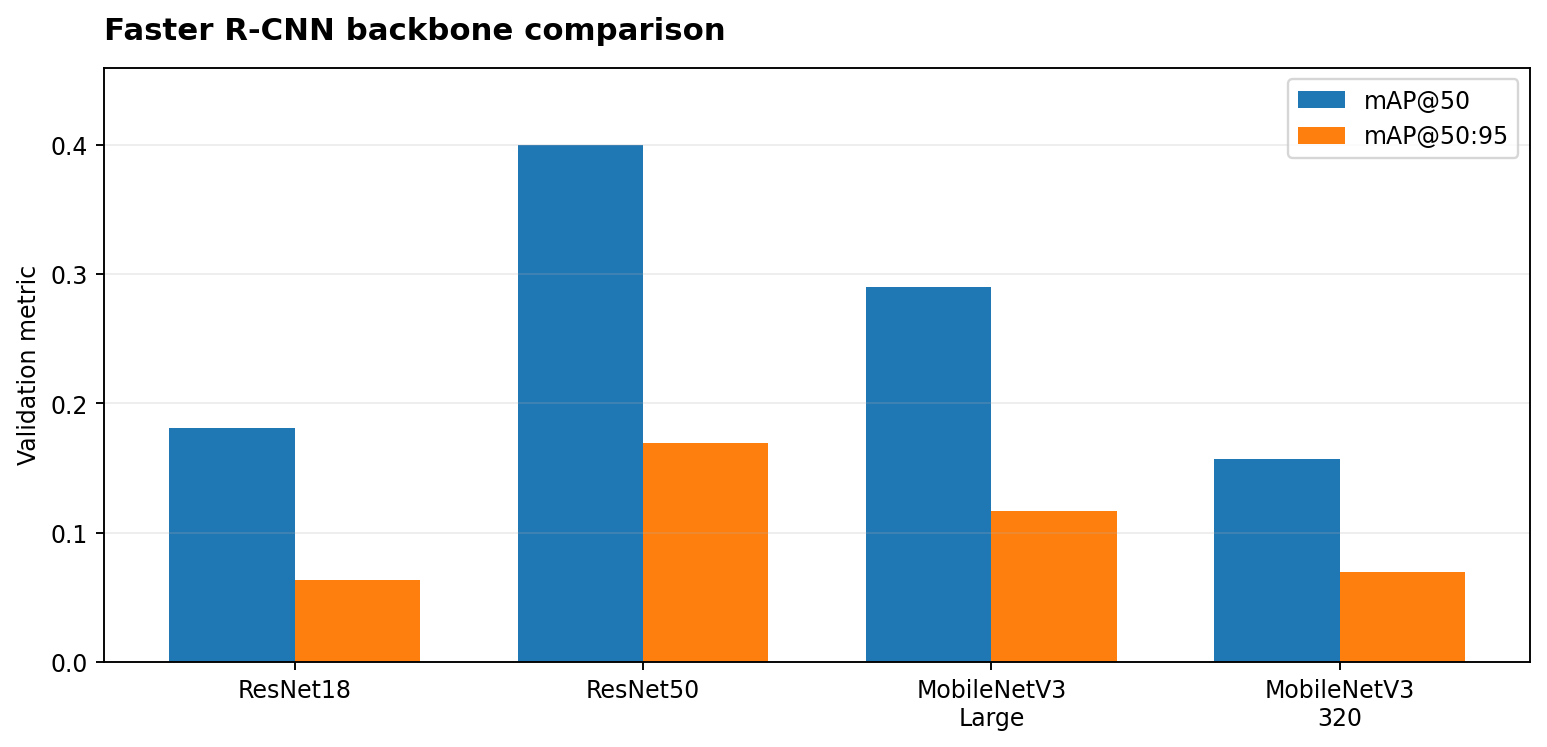

### 10.2 Class-wise detector performance

The class-wise AP matrix reveals that the best backbone depends on the damage category. ResNet50-FPN leads on longitudinal cracks, transverse cracks, other corruption and potholes, while MobileNetV3-Large-FPN achieves the highest AP for alligator cracks. Pothole AP remains low across all four configurations, with a maximum of 0.1019 in this compact five-epoch experiment.
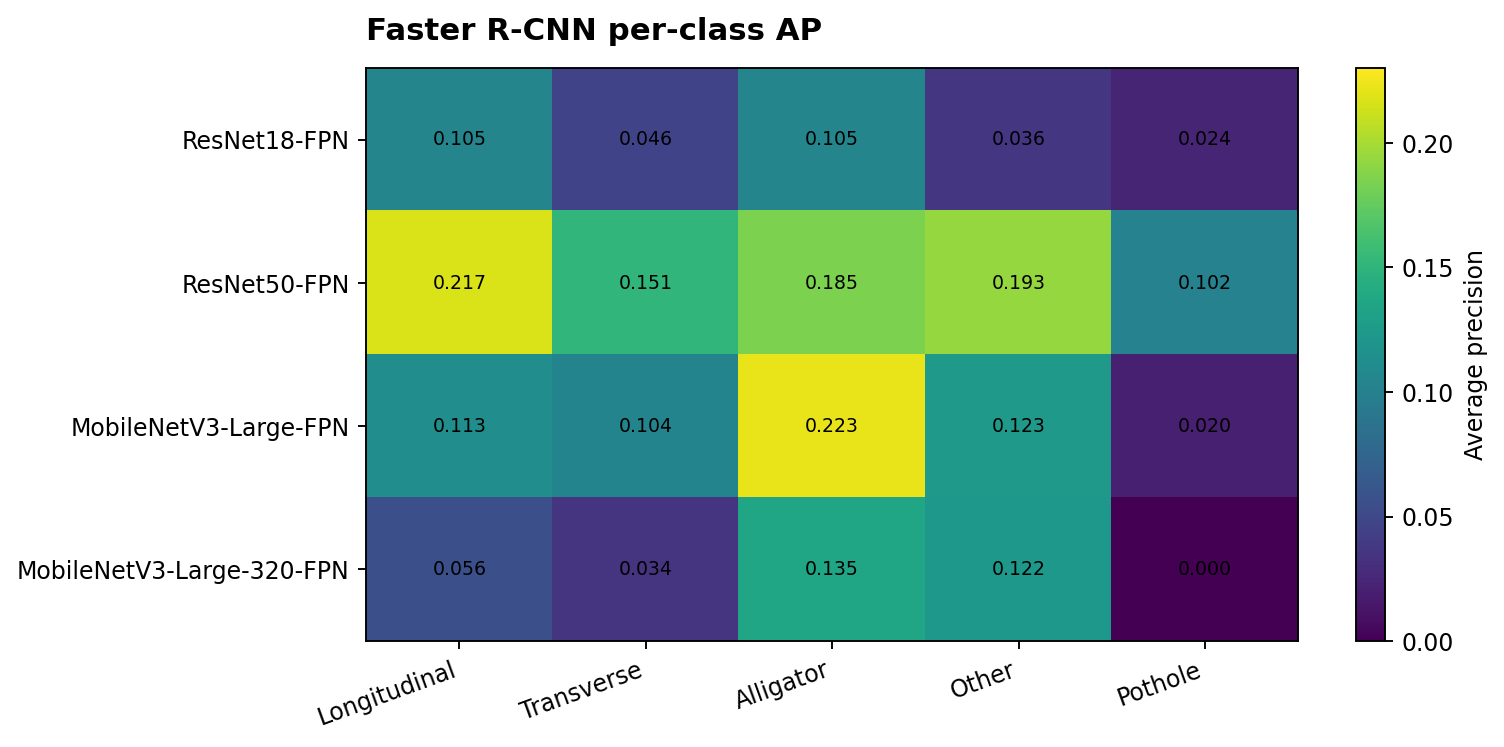

=== Overall Comparison ===
                 Backbone Params  mAP50  mAP50-95
             ResNet18-FPN  28.3M 0.1807    0.0632
             ResNet50-FPN  41.3M 0.3999    0.1697
    MobileNetV3-Large-FPN  19.0M 0.2901    0.1164
MobileNetV3-Large-320-FPN  19.0M 0.1568    0.0695

=== Per-Class AP Comparison ===
                 Backbone  Longitudinal Crack  Transverse Crack  Alligator Crack  Other Corruption  Pothole
             ResNet18-FPN              0.1046            0.0465           0.1047            0.0362   0.0239
             ResNet50-FPN              0.2170            0.1514           0.1848            0.1933   0.1019
    MobileNetV3-Large-FPN              0.1126            0.1037           0.2226            0.1231   0.0199
MobileNetV3-Large-320-FPN              0.0559            0.0342           0.1349            0.1223   0.0004


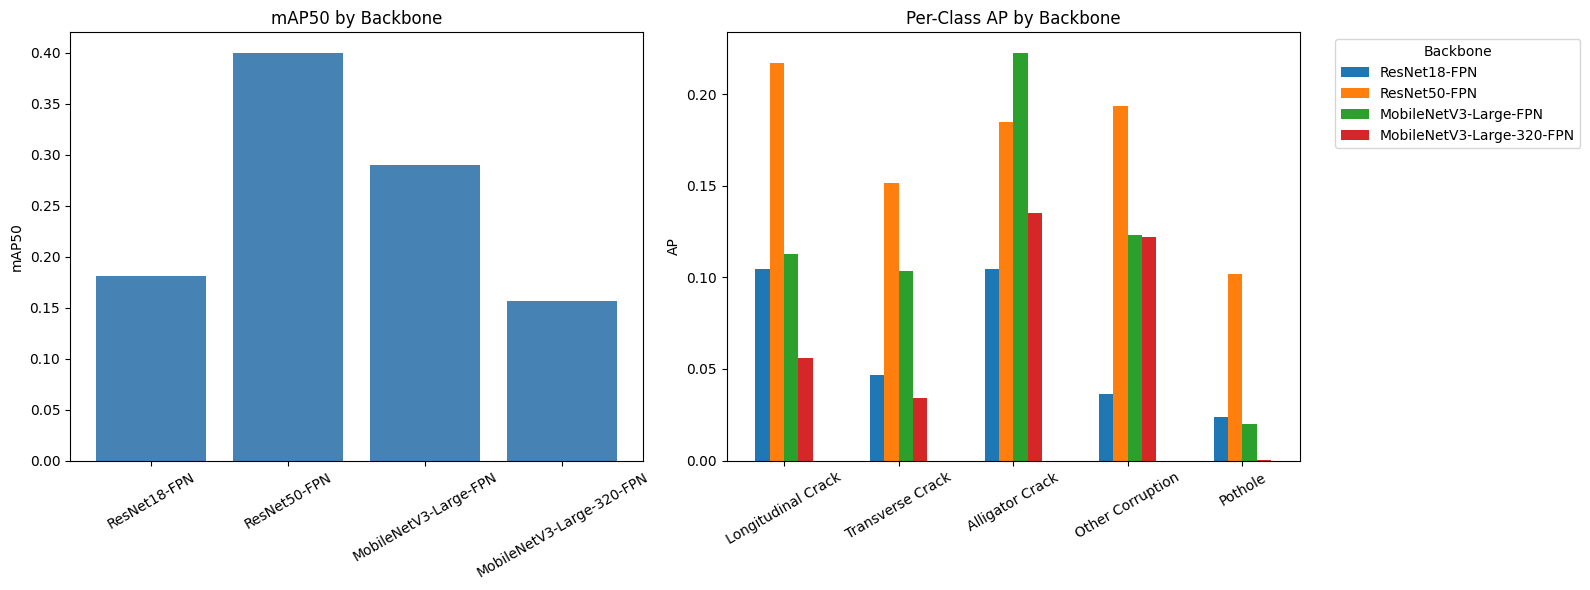


Saved comparison tables and chart to Drive.


In [ ]:
import pandas as pd

# ---------- Comparison table: overall metrics ----------
overall_data = {
    "Backbone": ["ResNet18-FPN", "ResNet50-FPN", "MobileNetV3-Large-FPN", "MobileNetV3-Large-320-FPN"],
    "Params": ["28.3M", "41.3M", "19.0M", "19.0M"],
    "mAP50": [0.1807, 0.3999, 0.2901, 0.1568],
    "mAP50-95": [0.0632, 0.1697, 0.1164, 0.0695],
}
overall_df = pd.DataFrame(overall_data)
print("=== Overall Comparison ===")
print(overall_df.to_string(index=False))

# ---------- Comparison table: per-class AP ----------
class_names = ['Longitudinal Crack', 'Transverse Crack', 'Alligator Crack', 'Other Corruption', 'Pothole']
per_class_data = {
    "Backbone": ["ResNet18-FPN", "ResNet50-FPN", "MobileNetV3-Large-FPN", "MobileNetV3-Large-320-FPN"],
    "Longitudinal Crack": [0.1046, 0.2170, 0.1126, 0.0559],
    "Transverse Crack":   [0.0465, 0.1514, 0.1037, 0.0342],
    "Alligator Crack":    [0.1047, 0.1848, 0.2226, 0.1349],
    "Other Corruption":   [0.0362, 0.1933, 0.1231, 0.1223],
    "Pothole":            [0.0239, 0.1019, 0.0199, 0.0004],
}
per_class_df = pd.DataFrame(per_class_data)
print("\n=== Per-Class AP Comparison ===")
print(per_class_df.to_string(index=False))

# ---------- Save both as CSV for your report ----------
import os
os.makedirs('/content/drive/MyDrive/road_damage_project/cnn_experiment', exist_ok=True)
overall_df.to_csv('/content/drive/MyDrive/road_damage_project/cnn_experiment/overall_comparison.csv', index=False)
per_class_df.to_csv('/content/drive/MyDrive/road_damage_project/cnn_experiment/per_class_comparison.csv', index=False)

# ---------- Optional: bar chart for visual comparison ----------
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].bar(overall_df['Backbone'], overall_df['mAP50'], color='steelblue')
axes[0].set_title('mAP50 by Backbone')
axes[0].set_ylabel('mAP50')
axes[0].tick_params(axis='x', rotation=30)

per_class_df.set_index('Backbone')[class_names].T.plot(kind='bar', ax=axes[1])
axes[1].set_title('Per-Class AP by Backbone')
axes[1].set_ylabel('AP')
axes[1].legend(title='Backbone', bbox_to_anchor=(1.05, 1), loc='upper left')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/road_damage_project/cnn_experiment/comparison_charts.png', dpi=150)
plt.show()

print("\nSaved comparison tables and chart to Drive.")

## 11. Research interpretation and limitations

The notebook supports three evidence-backed conclusions. First, the classical HOG + Linear SVM baseline provides a measurable image-level reference and exposes a relatively weak pothole F1 score. Second, the multi-source classical experiment produces a modest improvement in aggregate F1 on the original RDD2022 test split, although class-level changes are mixed. Third, among the four Faster R-CNN configurations, ResNet50-FPN provides the strongest aggregate validation mAP, while MobileNetV3-Large-FPN offers a smaller model with competitive but lower overall detection performance.

### Threats to validity

- **Task mismatch:** HOG/SVM metrics describe image-level multi-label classification; Faster R-CNN and YOLO metrics describe object localization. These metrics are not directly comparable.
- **Source/split asymmetry:** the RDD2024 training and validation folders are merged into the training partition, while validation is based on RDD2022. Cross-source generalization is therefore not independently measured.
- **Compact CNN experiment:** four Faster R-CNN configurations are trained for five epochs on a compact sample. The results are indicative of this protocol, not exhaustive architecture rankings.
- **Class imbalance:** potholes are the least frequent category in the processed annotation table and have low AP in the CNN experiment. Aggregate mAP alone would obscure this weakness.
- **Efficiency evidence:** parameter counts are available for the Faster R-CNN models, but measured latency, throughput, peak memory and FLOPs are not reported.
- **YOLO run evidence:** the training code records the configured schedule. Actual completed epochs and final metrics must be taken from the run artifacts.

### Final notebook takeaway

TarmacLook is best understood as a staged experimental framework: dataset auditing informs taxonomy harmonization; the classical baseline provides an interpretable reference; object detectors extend the task from image-level recognition to spatial localization; and architecture comparison reveals the accuracy–complexity and class-wise trade-offs that matter for road-damage monitoring. The next rigorous evaluation step is to complete and archive the YOLO run metrics, evaluate all final detectors on a common untouched test protocol, and report per-class AP/precision/recall together with measured inference efficiency.
